In [1]:

# ============================================================
#  PREPARAÇÃO DOS DADOS - MCA PENSE 2024
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Arquivo de entrada
arquivo = (
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "08_PENSE2024_MCA_COORDENADAS.feather"
)

# Carregar dados
df_mca = pd.read_feather(arquivo)

print("=" * 65)
print("BASE DE COORDENADAS MCA - PENSE 2024")
print("=" * 65)

print(f"\nDimensões da base: {df_mca.shape}")
print(f"Quantidade de registros: {len(df_mca):,}")
print(f"Quantidade de colunas: {len(df_mca.columns)}")

# Identificar automaticamente colunas de coordenadas MCA
padrao_mca = re.compile(
    r"(dim|dimension|coord|axis|eixo|factor|component)",
    re.IGNORECASE
)

colunas_numericas = df_mca.select_dtypes(
    include=[np.number]
).columns.tolist()

colunas_mca = [
    c for c in colunas_numericas
    if padrao_mca.search(str(c))
]

# Caso os nomes não identifiquem as dimensões,
# utilizar todas as colunas numéricas, exceto identificadores.
if len(colunas_mca) < 2:

    colunas_mca = [
        c for c in colunas_numericas
        if not re.search(
            r"(^id$|^id_|_id$|codigo|código|identificador)",
            str(c),
            re.IGNORECASE
        )
    ]

print("\nColunas utilizadas na análise MCA:")
print(colunas_mca)

if len(colunas_mca) < 2:
    raise ValueError(
        "Não foram encontradas pelo menos duas colunas numéricas "
        "para realizar a clusterização."
    )

# Criar matriz de coordenadas
X = df_mca[colunas_mca].copy()

# Substituir valores infinitos por NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Remover registros com coordenadas ausentes
mascara_validos = X.notna().all(axis=1)

X = X.loc[mascara_validos].copy()

# Preservar índice dos registros originais
indices_validos = X.index

print("\nResultado da preparação:")
print(f"Registros válidos: {len(X):,}")
print(f"Registros removidos: {len(df_mca) - len(X):,}")
print(f"Dimensões MCA utilizadas: {X.shape[1]}")

# Converter para matriz NumPy
X_array = X.to_numpy(dtype=float)

# Identificar as duas primeiras dimensões para gráficos
dim1 = colunas_mca[0]
dim2 = colunas_mca[1]

print(f"\nGráficos utilizarão: {dim1} x {dim2}")


BASE DE COORDENADAS MCA - PENSE 2024

Dimensões da base: (118036, 21)
Quantidade de registros: 118,036
Quantidade de colunas: 21

Colunas utilizadas na análise MCA:
['indice_original', 'MCA_1', 'MCA_2', 'MCA_3', 'MCA_4', 'MCA_5', 'MCA_6', 'MCA_7', 'MCA_8', 'MCA_9', 'MCA_10', 'MCA_11', 'MCA_12', 'MCA_13', 'MCA_14', 'MCA_15', 'MCA_16', 'MCA_17', 'MCA_18', 'MCA_19', 'MCA_20']

Resultado da preparação:
Registros válidos: 118,036
Registros removidos: 0
Dimensões MCA utilizadas: 21

Gráficos utilizarão: indice_original x MCA_1


HAC - HIERARCHICAL AGGLOMERATIVE CLUSTERING

Registros utilizados: 5,000

Calculando dendrograma...


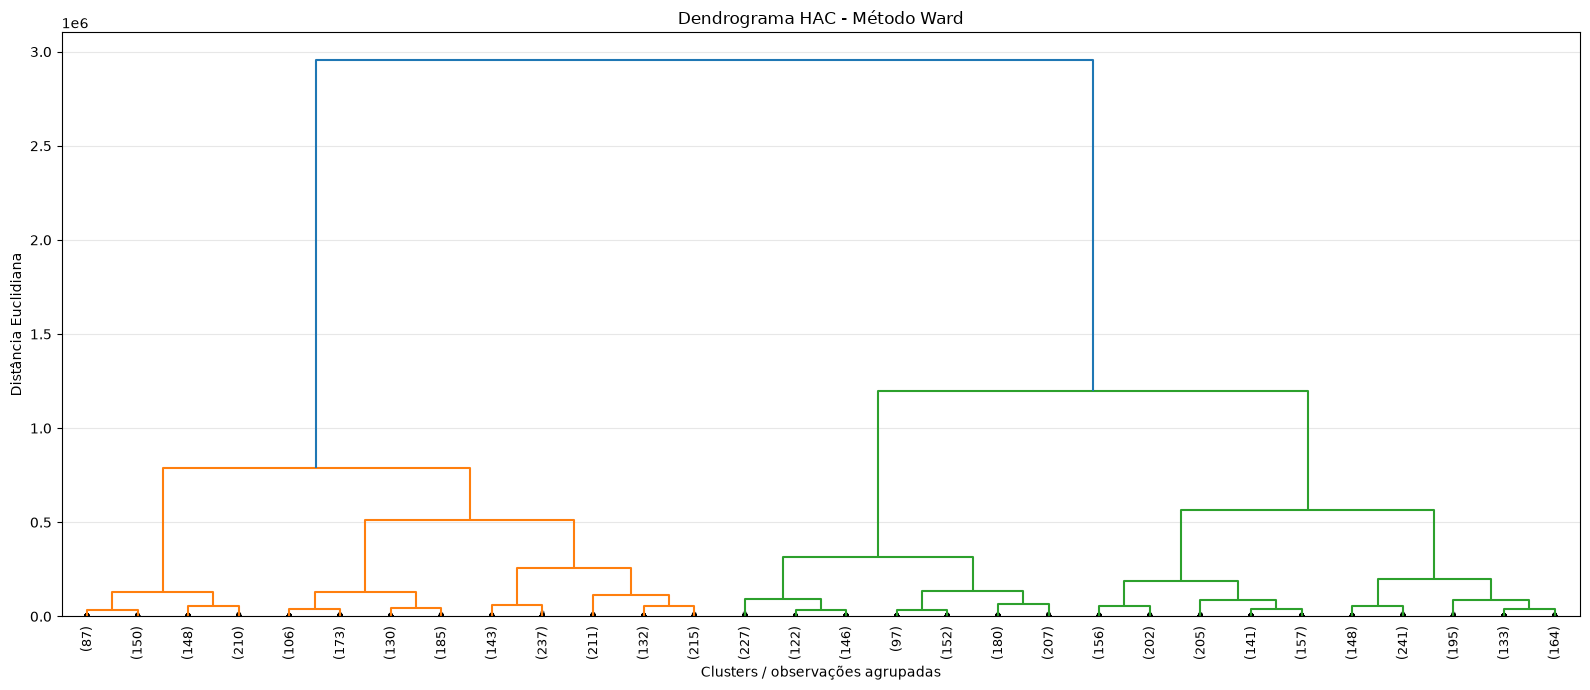


Avaliando diferentes números de clusters...

K=2 | Silhouette=0.6230
K=3 | Silhouette=0.5374
K=4 | Silhouette=0.5127
K=5 | Silhouette=0.5045
K=6 | Silhouette=0.5161
K=7 | Silhouette=0.5224
K=8 | Silhouette=0.5297
K=9 | Silhouette=0.5191
K=10 | Silhouette=0.5194

RESULTADOS HAC

Melhor número de clusters: 2
Silhouette Score: 0.6230

Distribuição dos clusters:
Cluster_HAC
0    2873
1    2127
Name: count, dtype: int64

Tabela comparativa:


,Clusters,Silhouette
0,2,0.6230
1,3,0.5374
2,4,0.5127
3,5,0.5045
4,6,0.5161
5,7,0.5224
6,8,0.5297
7,9,0.5191
8,10,0.5194


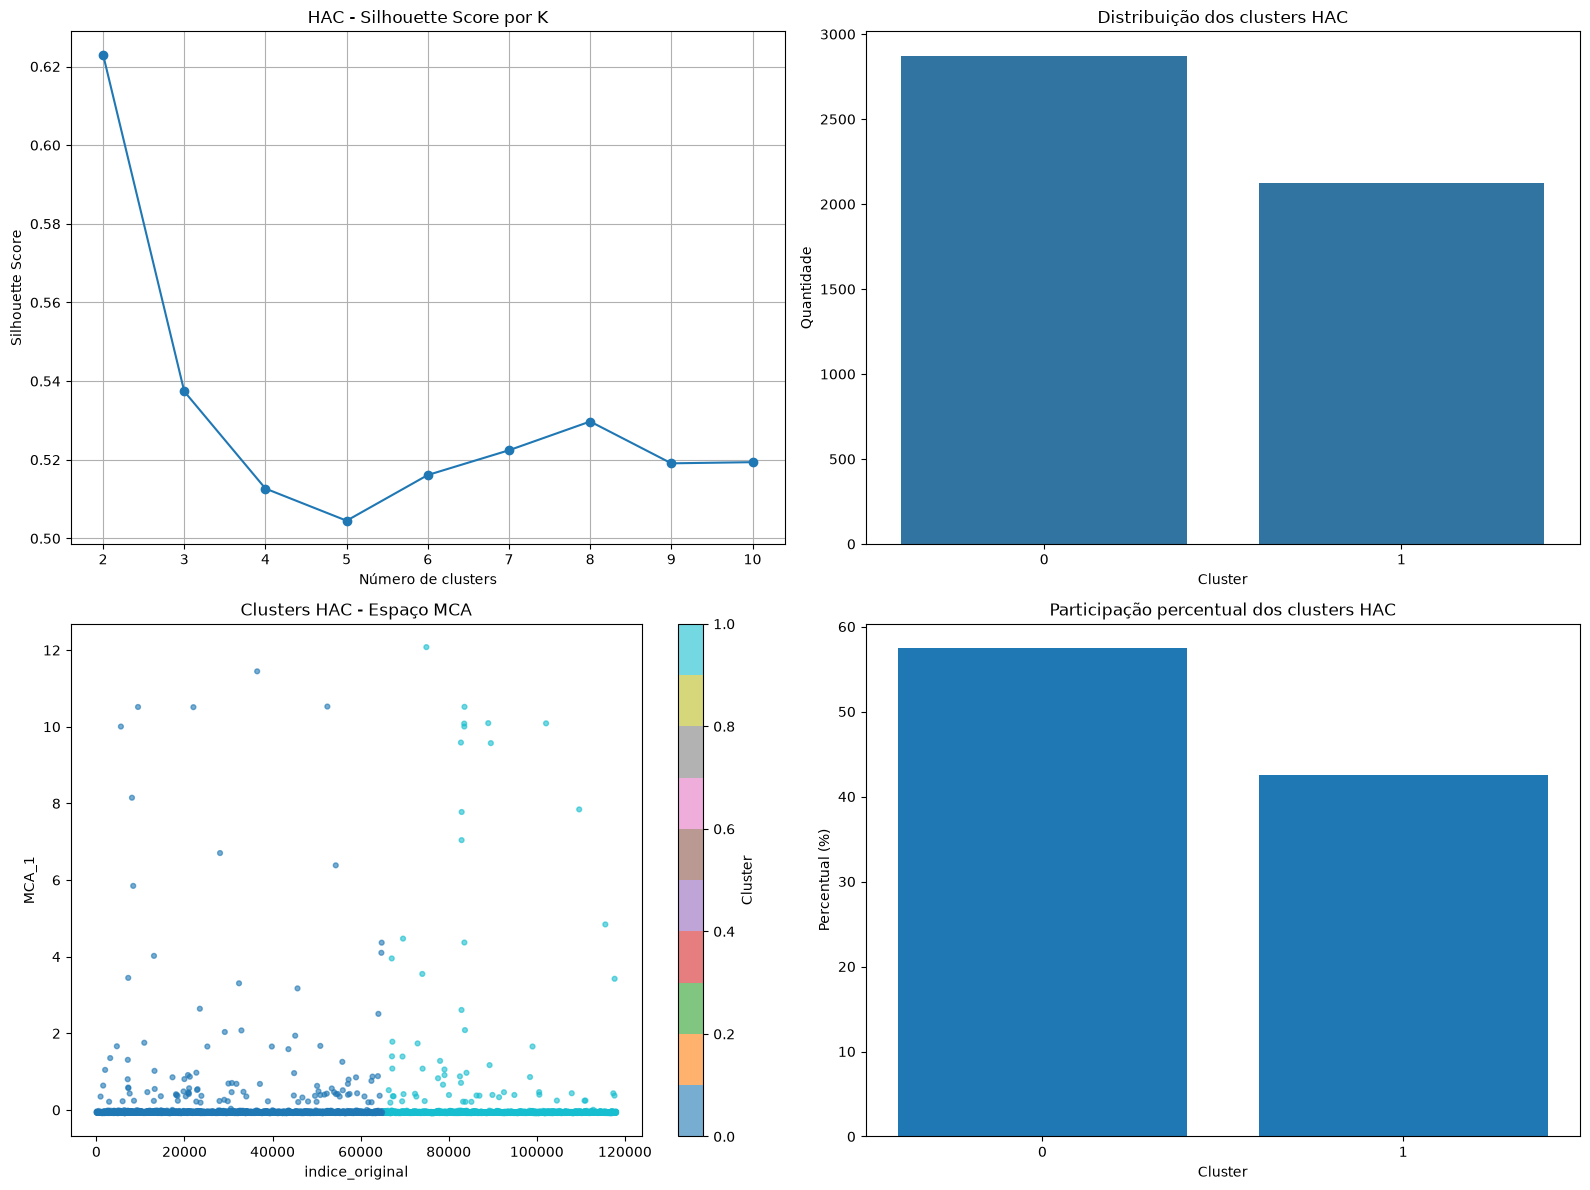


Médias das coordenadas MCA por cluster:


,indice_original,MCA_1,MCA_2,MCA_3,MCA_4,MCA_5,MCA_6,MCA_7,MCA_8,MCA_9,...,MCA_11,MCA_12,MCA_13,MCA_14,MCA_15,MCA_16,MCA_17,MCA_18,MCA_19,MCA_20
Cluster_HAC,,,,,,,,,,,,,,,,,,,,,
0,31856.4323,-0.0017,0.0185,-0.0052,-0.0136,0.0193,0.0032,0.0005,0.0203,0.0202,...,-0.0052,0.0139,0.0007,-0.0116,-0.0022,0.0039,-0.0078,-0.0122,-0.0066,-0.0005
1,91627.5905,0.0141,-0.0248,0.0193,0.0296,-0.0235,-0.0056,-0.0009,-0.0402,-0.0237,...,-0.0022,-0.0263,-0.0015,0.0156,0.0058,0.0003,0.0020,0.0140,0.0064,-0.0090


In [2]:

# ============================================================
#  HAC - HIERARCHICAL AGGLOMERATIVE CLUSTERING
#  PENSE 2024 - COORDENADAS MCA
# ============================================================

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

# Parâmetros
MAX_AMOSTRA_HAC = 5000
K_MIN_HAC = 2
K_MAX_HAC = 10

# Selecionar amostra
if len(X) > MAX_AMOSTRA_HAC:

    rng = np.random.RandomState(42)

    indices_hac = rng.choice(
        len(X),
        MAX_AMOSTRA_HAC,
        replace=False
    )

else:
    indices_hac = np.arange(len(X))

X_hac = X_array[indices_hac]

print("=" * 65)
print("HAC - HIERARCHICAL AGGLOMERATIVE CLUSTERING")
print("=" * 65)

print(f"\nRegistros utilizados: {len(X_hac):,}")

# ============================================================
# DENDROGRAMA
# ============================================================

print("\nCalculando dendrograma...")

# Ward minimiza o aumento da variância intra-cluster
matriz_linkage = linkage(
    X_hac,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(16, 7))

dendrogram(
    matriz_linkage,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)

plt.title("Dendrograma HAC - Método Ward")
plt.xlabel("Clusters / observações agrupadas")
plt.ylabel("Distância Euclidiana")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# TESTAR DIFERENTES NÚMEROS DE CLUSTERS
# ============================================================

resultados_hac = []
modelos_hac = {}

print("\nAvaliando diferentes números de clusters...\n")

for k in range(K_MIN_HAC, K_MAX_HAC + 1):

    modelo = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean"
    )

    labels = modelo.fit_predict(X_hac)

    score = silhouette_score(
        X_hac,
        labels
    )

    modelos_hac[k] = modelo

    resultados_hac.append({
        "Clusters": k,
        "Silhouette": score
    })

    print(f"K={k} | Silhouette={score:.4f}")

df_hac = pd.DataFrame(resultados_hac)

# Melhor K pelo Silhouette
melhor_k_hac = int(
    df_hac.loc[
        df_hac["Silhouette"].idxmax(),
        "Clusters"
    ]
)

# Modelo final
modelo_hac = modelos_hac[melhor_k_hac]

clusters_hac = modelo_hac.labels_

# ============================================================
# RESULTADOS
# ============================================================

df_resultado_hac = df_mca.iloc[
    indices_validos[indices_hac]
].copy()

df_resultado_hac["Cluster_HAC"] = clusters_hac

print("\n" + "=" * 65)
print("RESULTADOS HAC")
print("=" * 65)

print(f"\nMelhor número de clusters: {melhor_k_hac}")

print(
    f"Silhouette Score: "
    f"{df_hac['Silhouette'].max():.4f}"
)

print("\nDistribuição dos clusters:")

print(
    df_resultado_hac["Cluster_HAC"]
    .value_counts()
    .sort_index()
)

print("\nTabela comparativa:")

display(df_hac.round(4))

# ============================================================
# GRÁFICOS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1 - Silhouette por K
axes[0, 0].plot(
    df_hac["Clusters"],
    df_hac["Silhouette"],
    marker="o"
)

axes[0, 0].set_title("HAC - Silhouette Score por K")
axes[0, 0].set_xlabel("Número de clusters")
axes[0, 0].set_ylabel("Silhouette Score")
axes[0, 0].grid(True)

# 2 - Distribuição
sns.countplot(
    x="Cluster_HAC",
    data=df_resultado_hac,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Distribuição dos clusters HAC")
axes[0, 1].set_xlabel("Cluster")
axes[0, 1].set_ylabel("Quantidade")

# 3 - Coordenadas MCA
scatter = axes[1, 0].scatter(
    X_hac[:, 0],
    X_hac[:, 1],
    c=clusters_hac,
    cmap="tab10",
    s=12,
    alpha=0.6
)

axes[1, 0].set_title("Clusters HAC - Espaço MCA")
axes[1, 0].set_xlabel(dim1)
axes[1, 0].set_ylabel(dim2)

plt.colorbar(scatter, ax=axes[1, 0], label="Cluster")

# 4 - Tamanho percentual dos clusters
percentuais = (
    df_resultado_hac["Cluster_HAC"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

axes[1, 1].bar(
    percentuais.index.astype(str),
    percentuais.values
)

axes[1, 1].set_title("Participação percentual dos clusters HAC")
axes[1, 1].set_xlabel("Cluster")
axes[1, 1].set_ylabel("Percentual (%)")

plt.tight_layout()
plt.show()

# ============================================================
# CENTROS MÉDIOS DOS CLUSTERS
# ============================================================

print("\nMédias das coordenadas MCA por cluster:")

display(
    df_resultado_hac.groupby("Cluster_HAC")[colunas_mca]
    .mean()
    .round(4)
)



AVALIAÇÃO AMPLIADA HAC - PENSE 2024

MÉTRICAS GERAIS


,Metrica,Resultado
0,Silhouette Score,6.230000e-01
1,Calinski-Harabasz,1.448735e+04
2,Davies-Bouldin,4.943000e-01
3,SSE Total,1.506342e+12
4,Distancia media entre centroides,5.977116e+04
5,Cluster Balance (entropia),9.839000e-01
6,Razao maior/menor cluster,1.350700e+00
7,Cophenetic Correlation,7.521000e-01



SILHOUETTE POR CLUSTER


,Media,Mediana,Desvio_Padrao,Minimo,Maximo,Observacoes
Cluster,,,,,,
0,0.5851,0.6928,0.2323,-0.2008,0.7483,2873
1,0.6742,0.7339,0.1426,0.2052,0.7852,2127



DISPERSÃO INTERNA POR CLUSTER


,Cluster,Quantidade,SSE,SSE_Medio
0,0,2873,9.975555e+11,3.472174e+08
1,1,2127,5.087867e+11,2.392039e+08



EQUILÍBRIO DOS CLUSTERS


,Cluster,Quantidade,Percentual
0,0,2873,57.46
1,1,2127,42.54



DISTÂNCIA ENTRE CENTROIDES


,Cluster 0,Cluster 1
Cluster 0,0.0000,59771.1582
Cluster 1,59771.1582,0.0000


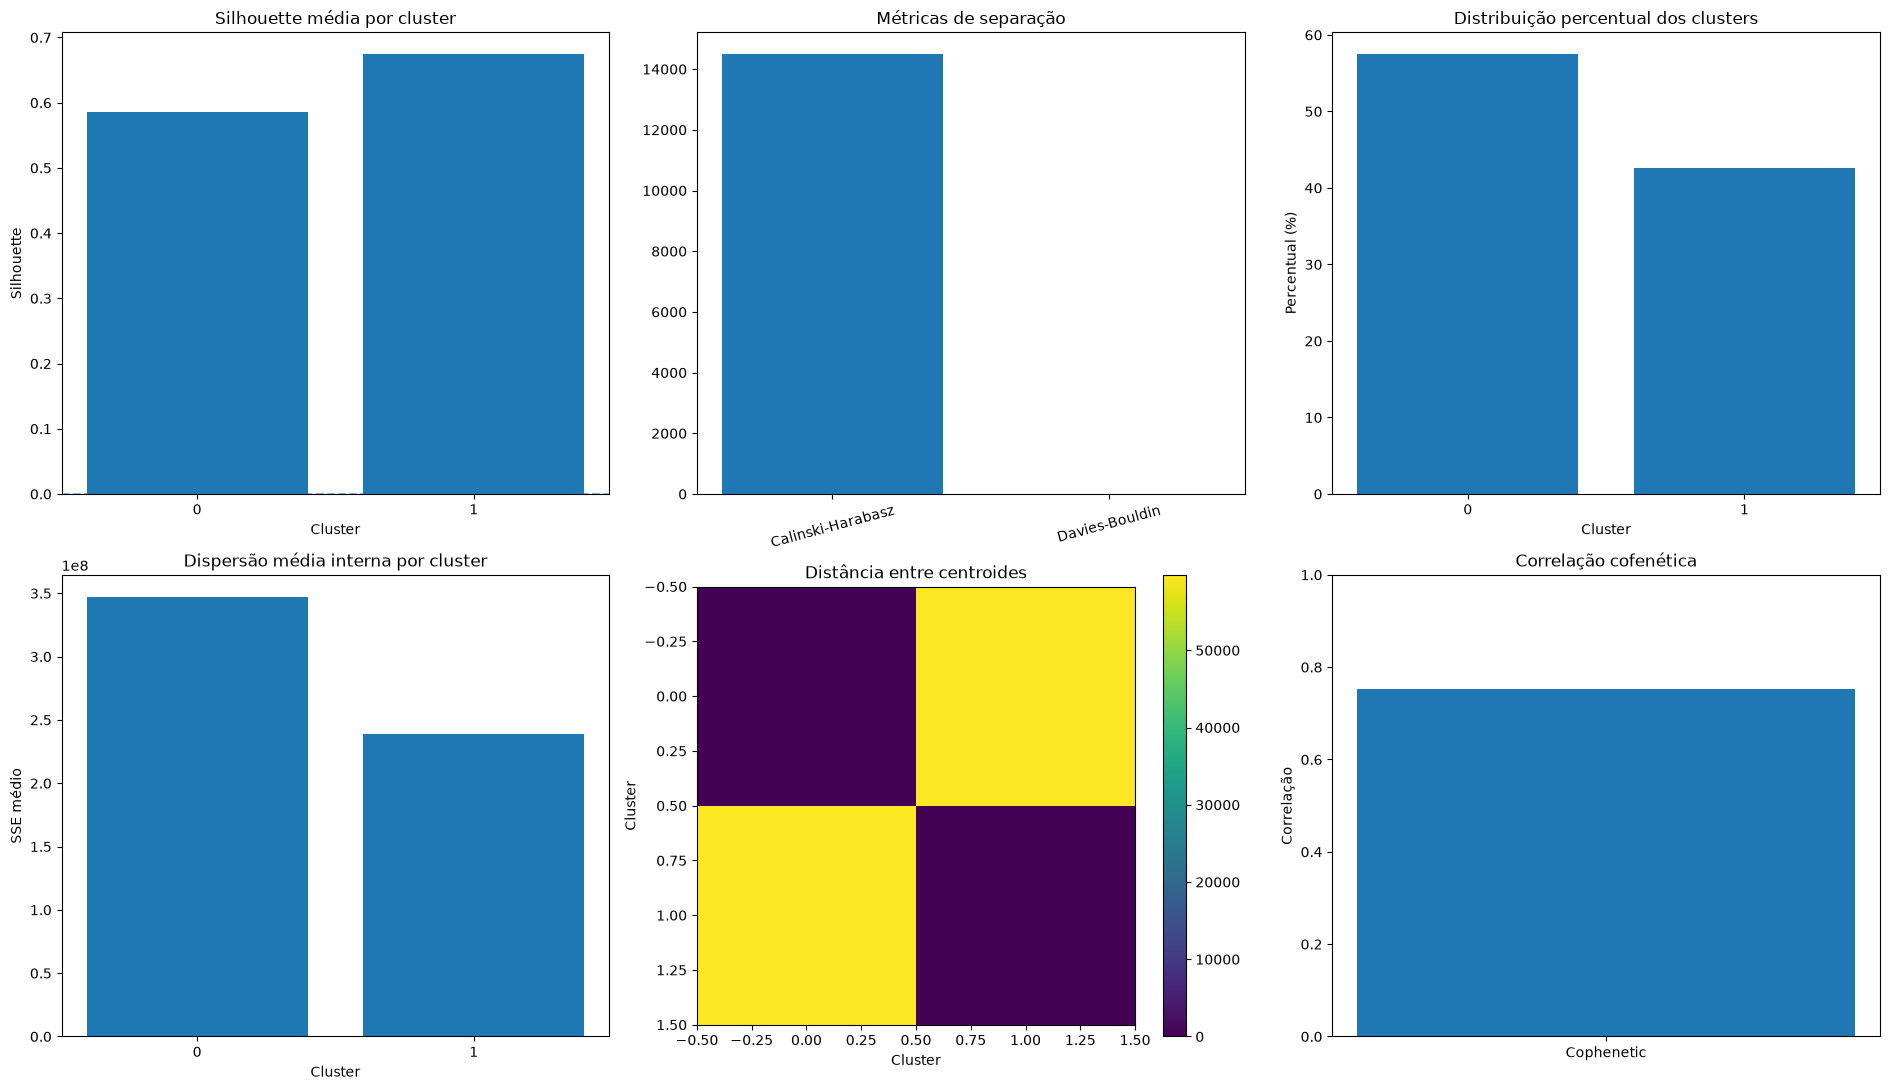


Avaliação ampliada HAC concluída.


In [3]:

# ============================================================
# 9. MÉTRICAS ADICIONAIS DE AVALIAÇÃO DO HAC
# PENSE 2024 - COORDENADAS MCA
# ============================================================

from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_samples,
    silhouette_score,
    adjusted_rand_score,
    pairwise_distances
)

from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist

# ------------------------------------------------------------
# 9.1. PREPARAÇÃO DOS DADOS
# ------------------------------------------------------------

# Utilizar exatamente a amostra e os clusters do HAC original

X_avaliacao_hac = X_hac
labels_hac = clusters_hac

K_FINAL_HAC = melhor_k_hac

# ------------------------------------------------------------
# 9.2. CALINSKI-HARABASZ INDEX
# ------------------------------------------------------------

ch_score_hac = calinski_harabasz_score(
    X_avaliacao_hac,
    labels_hac
)

# ------------------------------------------------------------
# 9.3. DAVIES-BOULDIN INDEX
# ------------------------------------------------------------

db_score_hac = davies_bouldin_score(
    X_avaliacao_hac,
    labels_hac
)

# ------------------------------------------------------------
# 9.4. SILHOUETTE POR CLUSTER
# ------------------------------------------------------------

silhouette_individual_hac = silhouette_samples(
    X_avaliacao_hac,
    labels_hac
)

df_silhouette_hac = pd.DataFrame({
    "Cluster": labels_hac,
    "Silhouette": silhouette_individual_hac
})

silhouette_clusters_hac = (
    df_silhouette_hac
    .groupby("Cluster")["Silhouette"]
    .agg(["mean", "median", "std", "min", "max", "count"])
    .round(4)
)

silhouette_clusters_hac.columns = [
    "Media",
    "Mediana",
    "Desvio_Padrao",
    "Minimo",
    "Maximo",
    "Observacoes"
]

# ------------------------------------------------------------
# 9.5. DISPERSÃO INTERNA - SSE
# ------------------------------------------------------------

dispersao_hac = []

centroides_hac = []

for k in range(K_FINAL_HAC):

    mascara = labels_hac == k

    dados_cluster = X_avaliacao_hac[mascara]

    centroide = dados_cluster.mean(axis=0)

    centroides_hac.append(centroide)

    distancias_quadradas = np.sum(
        (dados_cluster - centroide) ** 2,
        axis=1
    )

    dispersao_hac.append({
        "Cluster": k,
        "Quantidade": len(dados_cluster),
        "SSE": distancias_quadradas.sum(),
        "SSE_Medio": distancias_quadradas.mean()
    })

df_dispersao_hac = pd.DataFrame(dispersao_hac)

centroides_hac = np.array(centroides_hac)

SSE_TOTAL_HAC = df_dispersao_hac["SSE"].sum()

# ------------------------------------------------------------
# 9.6. EQUILÍBRIO DOS CLUSTERS
# ------------------------------------------------------------

tamanhos_hac = np.bincount(
    labels_hac,
    minlength=K_FINAL_HAC
)

percentuais_hac = (
    tamanhos_hac / len(labels_hac)
) * 100

df_balance_hac = pd.DataFrame({
    "Cluster": range(K_FINAL_HAC),
    "Quantidade": tamanhos_hac,
    "Percentual": percentuais_hac
})

# Razão entre maior e menor cluster
razao_balance_hac = (
    tamanhos_hac.max() / tamanhos_hac.min()
    if tamanhos_hac.min() > 0 else np.inf
)

# Entropia normalizada do tamanho dos clusters
proporcoes_hac = tamanhos_hac / tamanhos_hac.sum()

entropia_hac = -np.sum(
    proporcoes_hac[proporcoes_hac > 0] *
    np.log(proporcoes_hac[proporcoes_hac > 0])
)

entropia_balance_hac = (
    entropia_hac / np.log(K_FINAL_HAC)
    if K_FINAL_HAC > 1 else np.nan
)

# ------------------------------------------------------------
# 9.7. DISTÂNCIA ENTRE CENTROIDES
# ------------------------------------------------------------

distancias_centroides_hac = pairwise_distances(
    centroides_hac,
    metric="euclidean"
)

df_distancias_hac = pd.DataFrame(
    distancias_centroides_hac,
    index=[f"Cluster {k}" for k in range(K_FINAL_HAC)],
    columns=[f"Cluster {k}" for k in range(K_FINAL_HAC)]
)

# Média das distâncias entre centroides distintos
mascara_superior = np.triu(
    np.ones(distancias_centroides_hac.shape, dtype=bool),
    k=1
)

distancia_media_centroides_hac = (
    distancias_centroides_hac[mascara_superior].mean()
)

# ------------------------------------------------------------
# 9.8. CORRELAÇÃO COFENÉTICA
# ------------------------------------------------------------

# Mede quanto o dendrograma preserva as distâncias originais.
# O cálculo pode consumir memória em amostras grandes.

CALCULAR_COPHENETIC = True

if CALCULAR_COPHENETIC:

    distancia_original = pdist(
        X_avaliacao_hac,
        metric="euclidean"
    )

    correlacao_cophenetic, distancias_cophenetic = cophenet(
        matriz_linkage,
        distancia_original
    )

    del distancia_original
    del distancias_cophenetic

else:

    correlacao_cophenetic = np.nan

# ------------------------------------------------------------
# 9.9. RESULTADOS CONSOLIDADOS
# ------------------------------------------------------------

silhouette_medio_hac = silhouette_score(
    X_avaliacao_hac,
    labels_hac
)

resultados_metricas_hac = pd.DataFrame({

    "Metrica": [
        "Silhouette Score",
        "Calinski-Harabasz",
        "Davies-Bouldin",
        "SSE Total",
        "Distancia media entre centroides",
        "Cluster Balance (entropia)",
        "Razao maior/menor cluster",
        "Cophenetic Correlation"
    ],

    "Resultado": [
        silhouette_medio_hac,
        ch_score_hac,
        db_score_hac,
        SSE_TOTAL_HAC,
        distancia_media_centroides_hac,
        entropia_balance_hac,
        razao_balance_hac,
        correlacao_cophenetic
    ]
})

print("\n" + "=" * 75)
print("AVALIAÇÃO AMPLIADA HAC - PENSE 2024")
print("=" * 75)

print("\nMÉTRICAS GERAIS")

display(resultados_metricas_hac.round(4))

print("\nSILHOUETTE POR CLUSTER")

display(silhouette_clusters_hac)

print("\nDISPERSÃO INTERNA POR CLUSTER")

display(df_dispersao_hac.round(4))

print("\nEQUILÍBRIO DOS CLUSTERS")

display(df_balance_hac.round(2))

print("\nDISTÂNCIA ENTRE CENTROIDES")

display(df_distancias_hac.round(4))

# ------------------------------------------------------------
# 9.10. GRÁFICOS DAS MÉTRICAS
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# Gráfico 1 - Silhouette por cluster

axes[0, 0].bar(
    silhouette_clusters_hac.index.astype(str),
    silhouette_clusters_hac["Media"]
)

axes[0, 0].axhline(
    0,
    linestyle="--",
    alpha=0.5
)

axes[0, 0].set_title("Silhouette média por cluster")
axes[0, 0].set_xlabel("Cluster")
axes[0, 0].set_ylabel("Silhouette")

# Gráfico 2 - Calinski-Harabasz e Davies-Bouldin

axes[0, 1].bar(
    ["Calinski-Harabasz", "Davies-Bouldin"],
    [ch_score_hac, db_score_hac]
)

axes[0, 1].set_title("Métricas de separação")
axes[0, 1].tick_params(axis="x", rotation=15)

# Gráfico 3 - Distribuição dos clusters

axes[0, 2].bar(
    df_balance_hac["Cluster"].astype(str),
    df_balance_hac["Percentual"]
)

axes[0, 2].set_title("Distribuição percentual dos clusters")
axes[0, 2].set_xlabel("Cluster")
axes[0, 2].set_ylabel("Percentual (%)")

# Gráfico 4 - Dispersão interna

axes[1, 0].bar(
    df_dispersao_hac["Cluster"].astype(str),
    df_dispersao_hac["SSE_Medio"]
)

axes[1, 0].set_title("Dispersão média interna por cluster")
axes[1, 0].set_xlabel("Cluster")
axes[1, 0].set_ylabel("SSE médio")

# Gráfico 5 - Distância entre centroides

im = axes[1, 1].imshow(
    distancias_centroides_hac,
    cmap="viridis"
)

axes[1, 1].set_title("Distância entre centroides")
axes[1, 1].set_xlabel("Cluster")
axes[1, 1].set_ylabel("Cluster")

plt.colorbar(im, ax=axes[1, 1])

# Gráfico 6 - Correlação cofenética

if not np.isnan(correlacao_cophenetic):

    axes[1, 2].bar(
        ["Cophenetic"],
        [correlacao_cophenetic]
    )

    axes[1, 2].set_ylim(0, 1)

    axes[1, 2].set_title("Correlação cofenética")
    axes[1, 2].set_ylabel("Correlação")

else:

    axes[1, 2].text(
        0.5, 0.5,
        "Não calculada",
        ha="center",
        va="center"
    )

    axes[1, 2].set_title("Correlação cofenética")
    axes[1, 2].set_axis_off()

plt.tight_layout()
plt.show()

print("\nAvaliação ampliada HAC concluída.")


Clusters identificados: [np.int64(0), np.int64(1)]
Total de indivíduos: 5000

Analisando 1/39: CAPITAL - indica se é município da capital


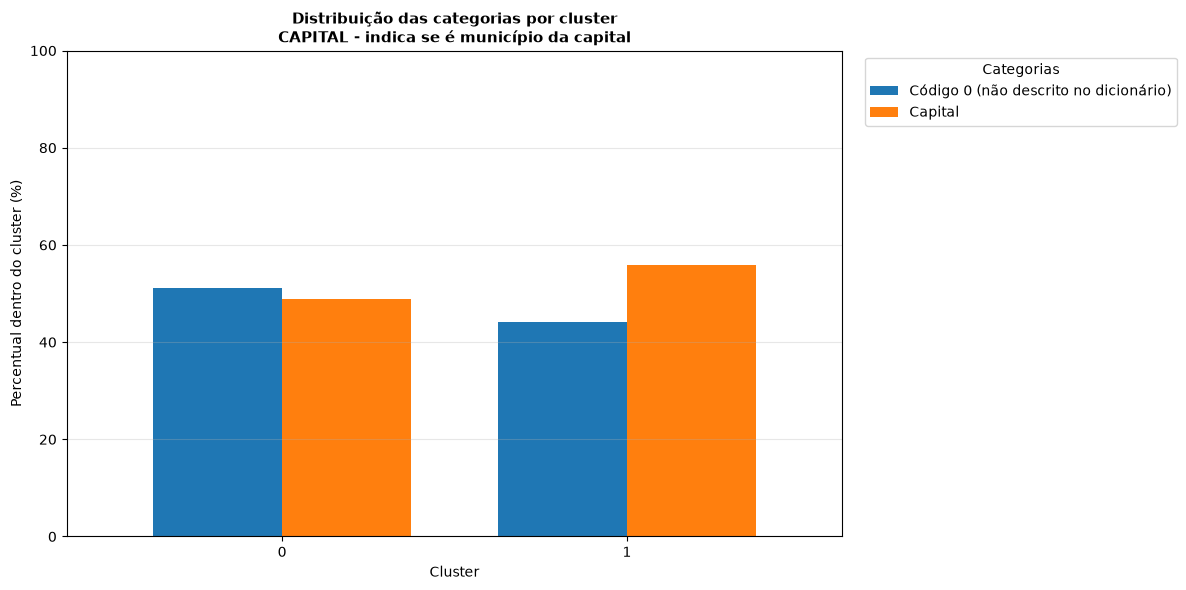


Analisando 2/39: B01001A - Qual é o seu sexo?


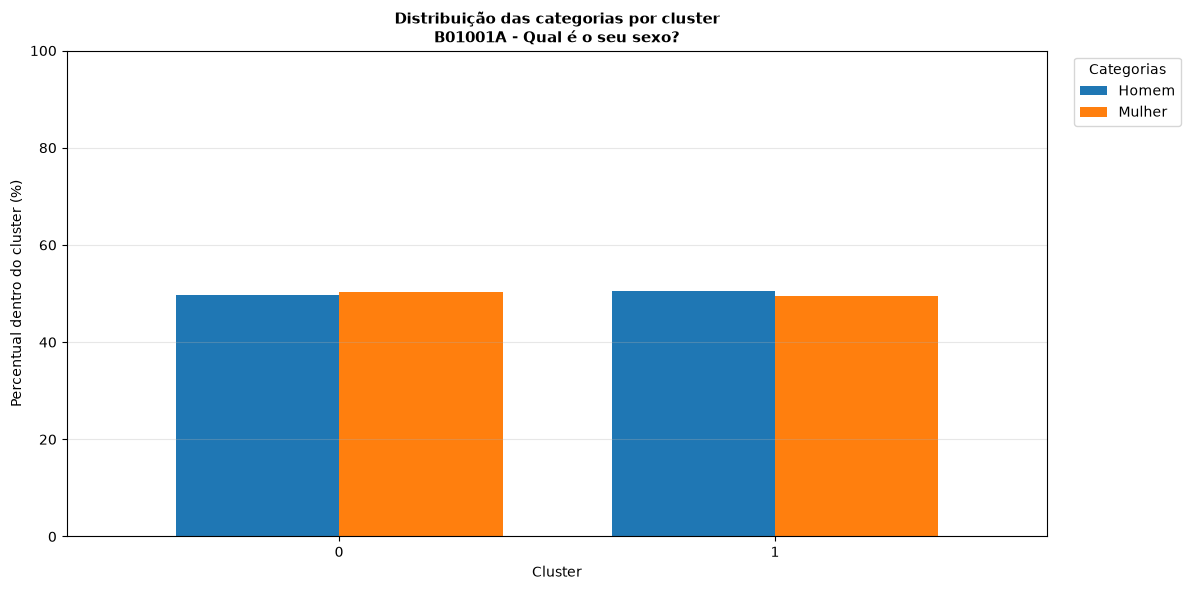


Analisando 3/39: IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS


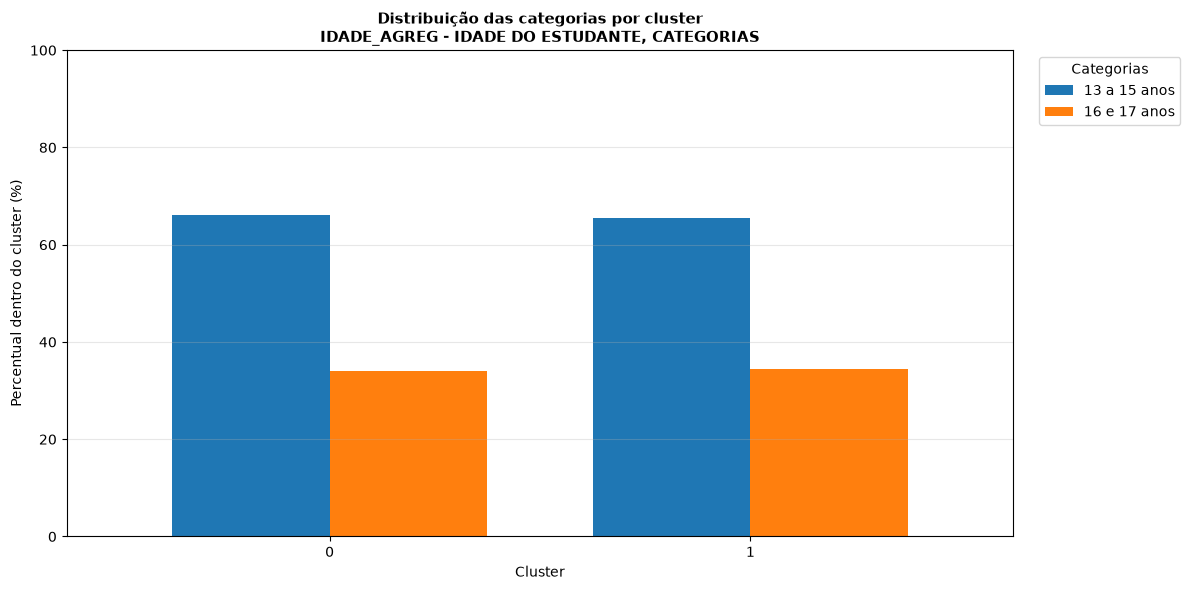


Analisando 4/39: B01002 - Qual é a sua cor ou raça?


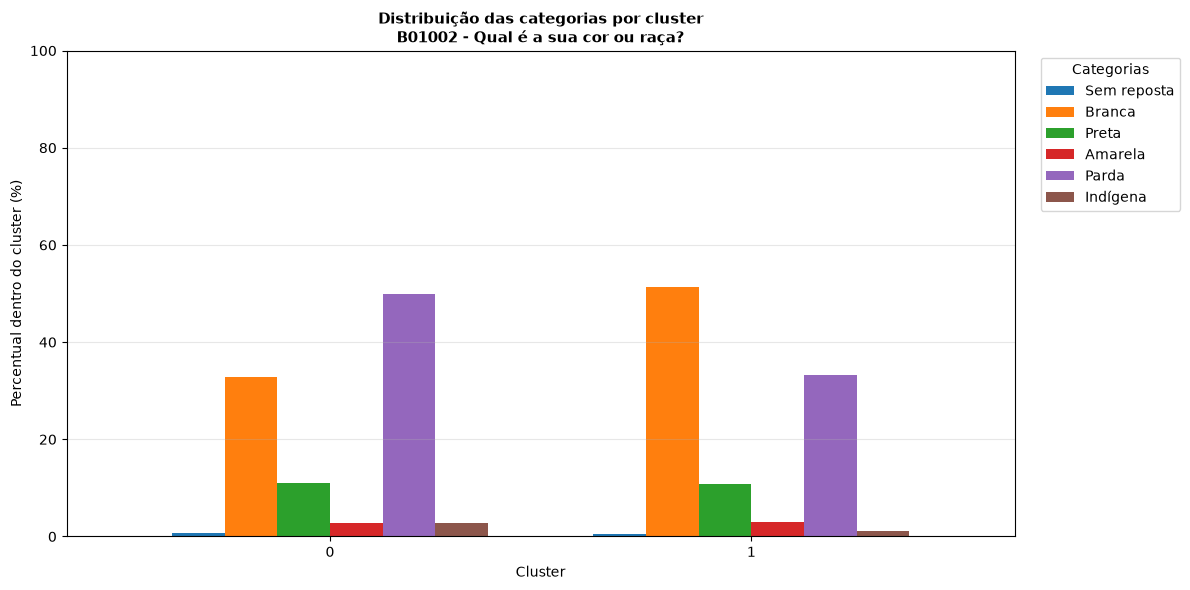


Analisando 5/39: B01006 - Você mora com sua mãe?


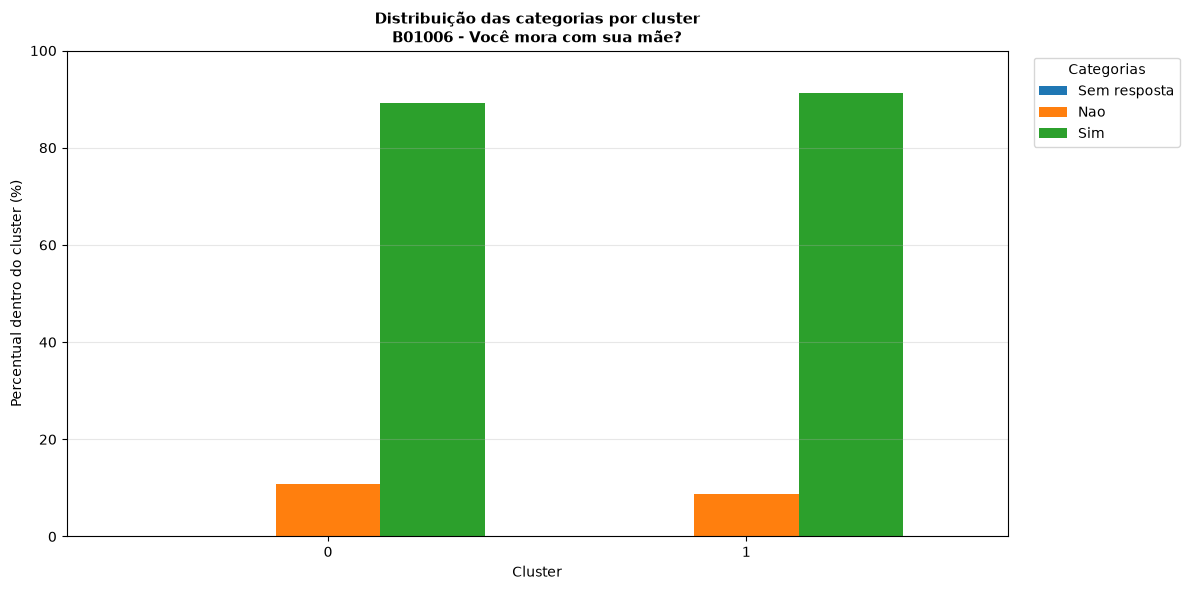


Analisando 6/39: B01007 - Você mora com seu pai?


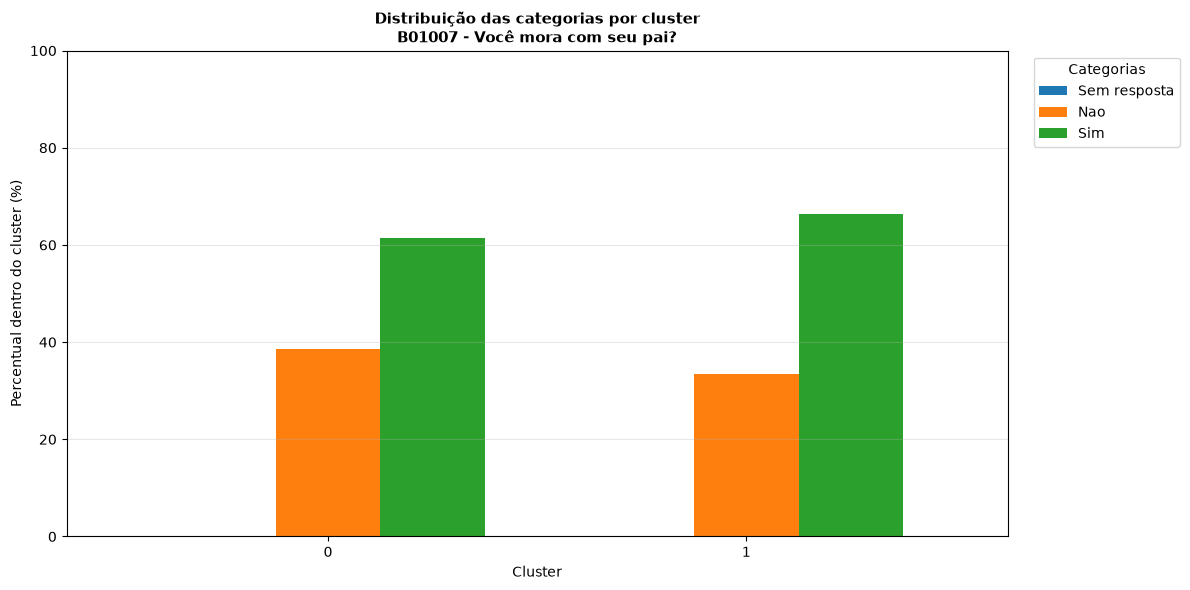


Analisando 7/39: B01015B - Na sua casa tem computador ou notebook?


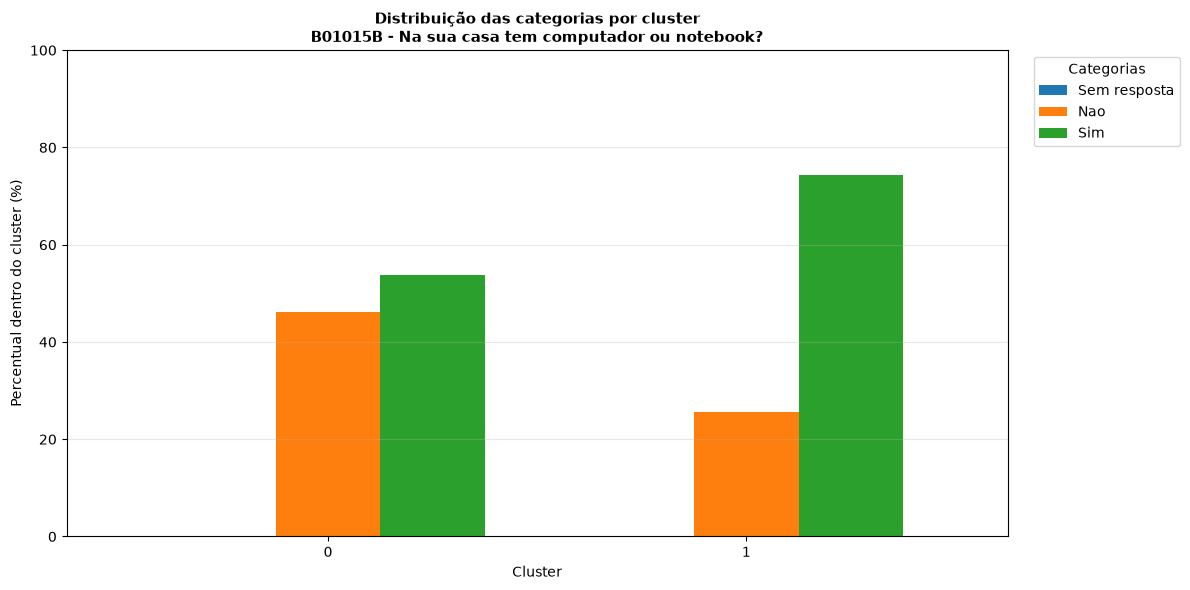


Analisando 8/39: B01016 - Você tem acesso à internet em sua casa?


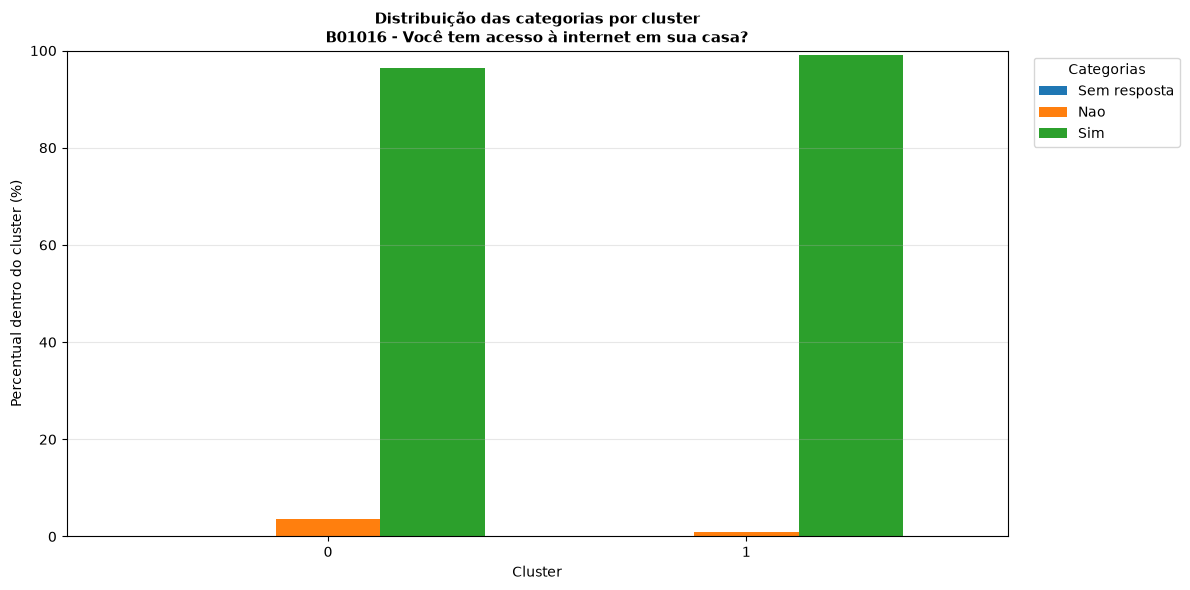


Analisando 9/39: B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?


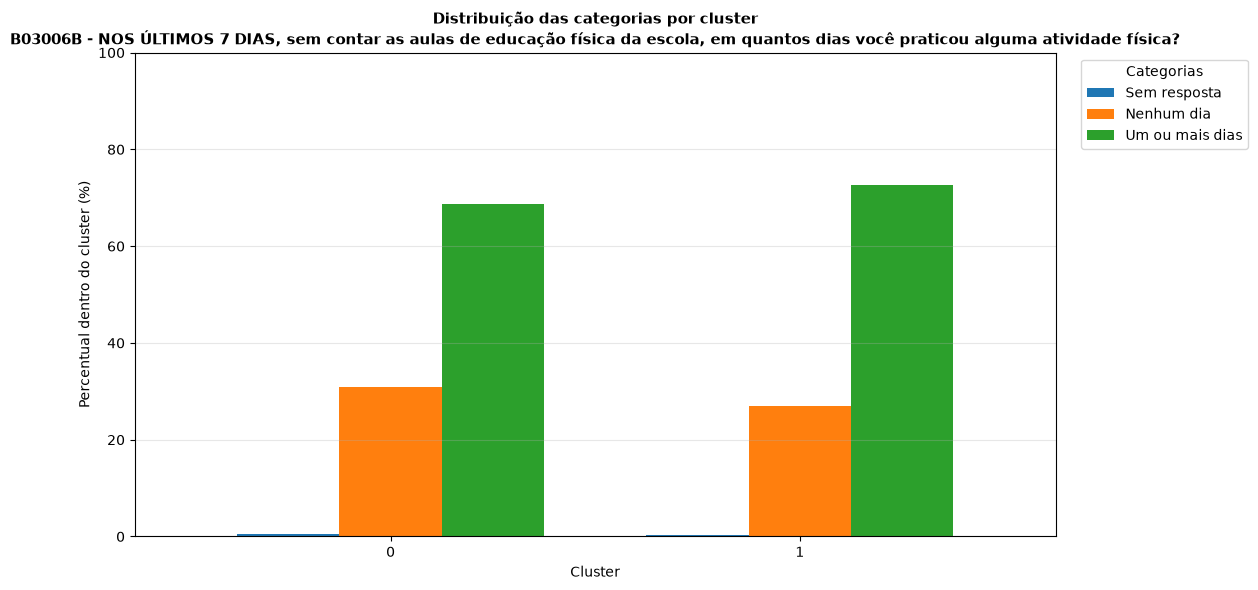


Analisando 10/39: B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)


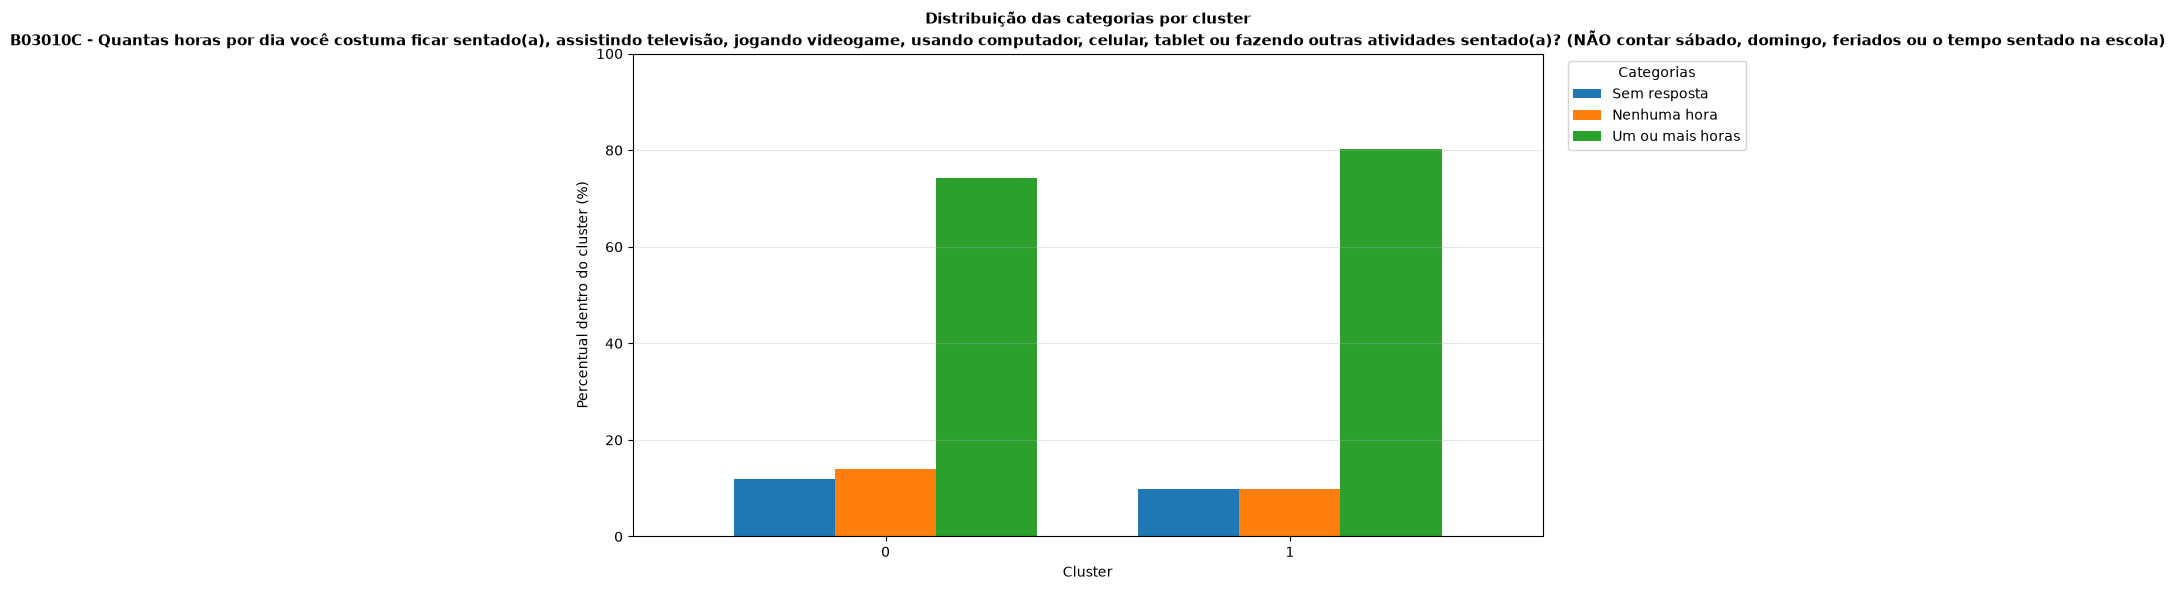


Analisando 11/39: B05002A - Alguma vez na vida você tomou um copo ou uma dose de bebida alcoólica?


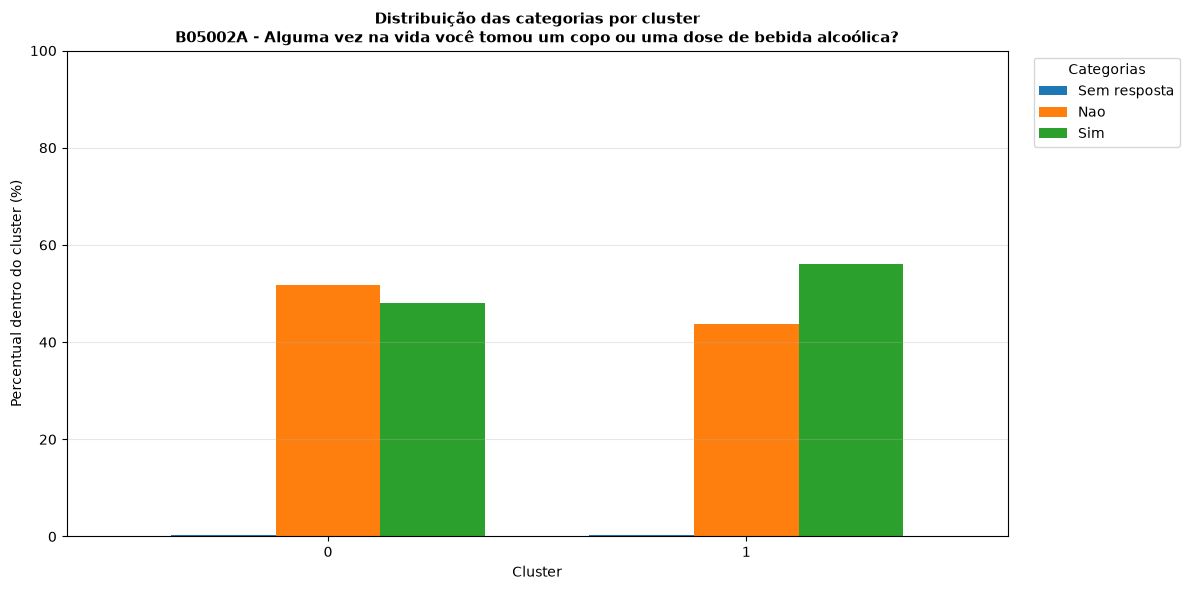


Analisando 12/39: B07002 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável sabia realmente o que você estava fazendo em seu tempo livre?


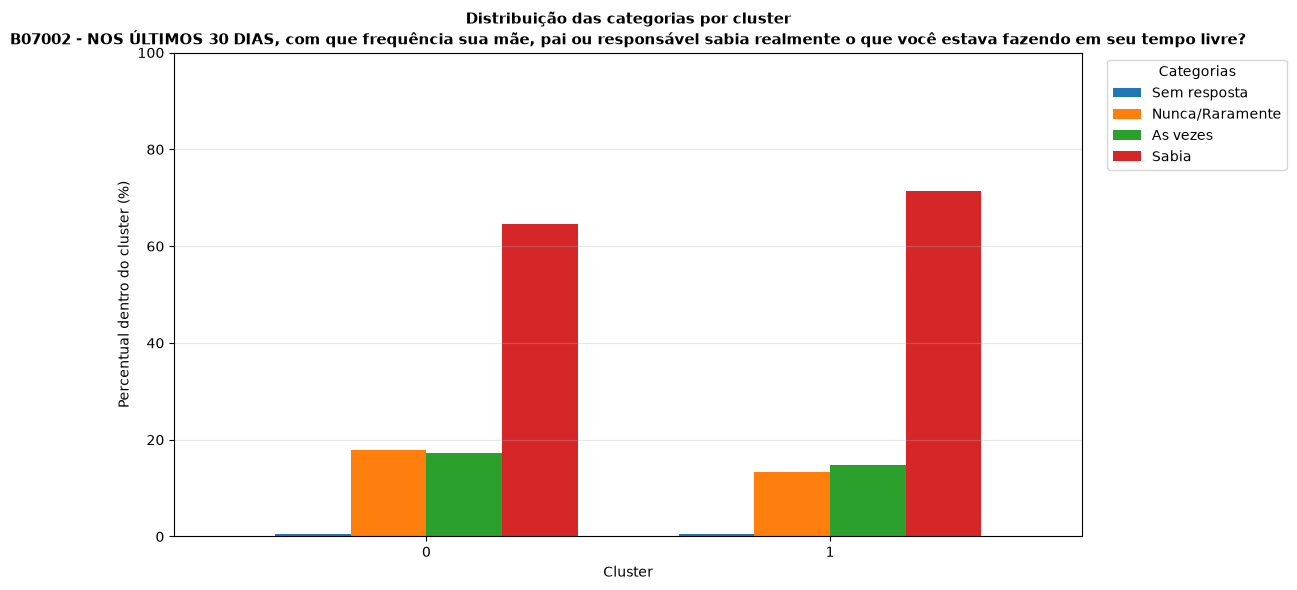


Analisando 13/39: B07004 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável entendeu suas preocupações e problemas?


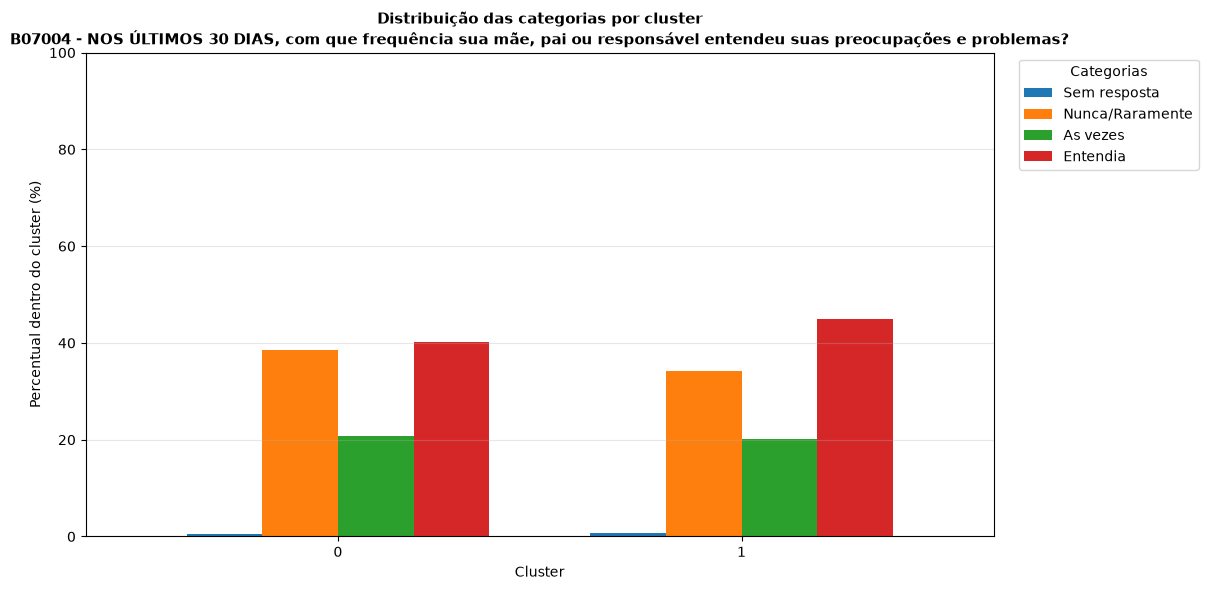


Analisando 14/39: B07005 - NOS ÚLTIMOS 30 DIAS, com que frequência seus pais ou responsáveis mexeram em suas coisas sem a sua concordância?


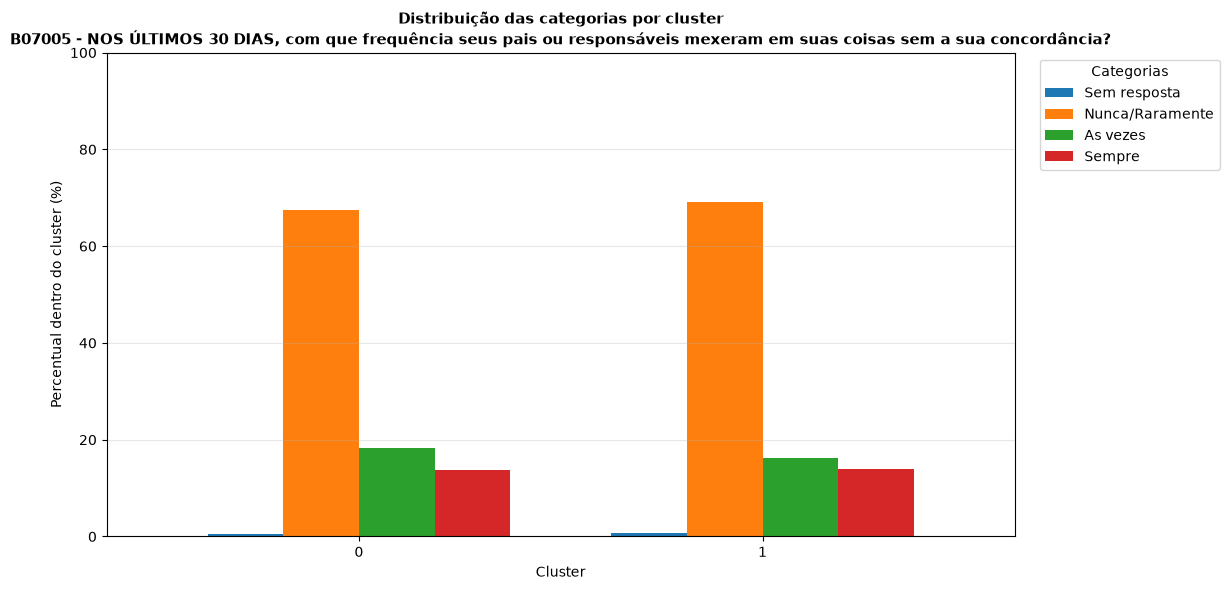


Analisando 15/39: B07006 - NOS ÚLTIMOS 30 DIAS, com que frequência os colegas de sua escola trataram você bem e/ou foram prestativos com você?


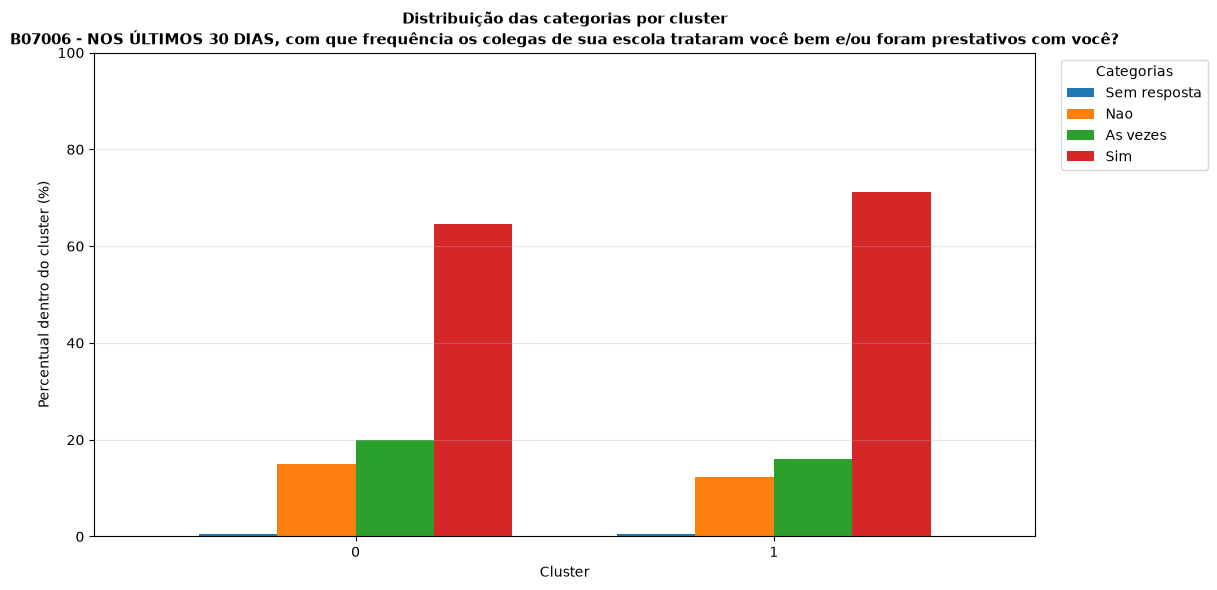


Analisando 16/39: B07007B - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola o esculachou, zoou, mangou, intimidou ou caçoou tanto que você ficou magoado, incomodado, aborrecido, ofendido ou humilhado?


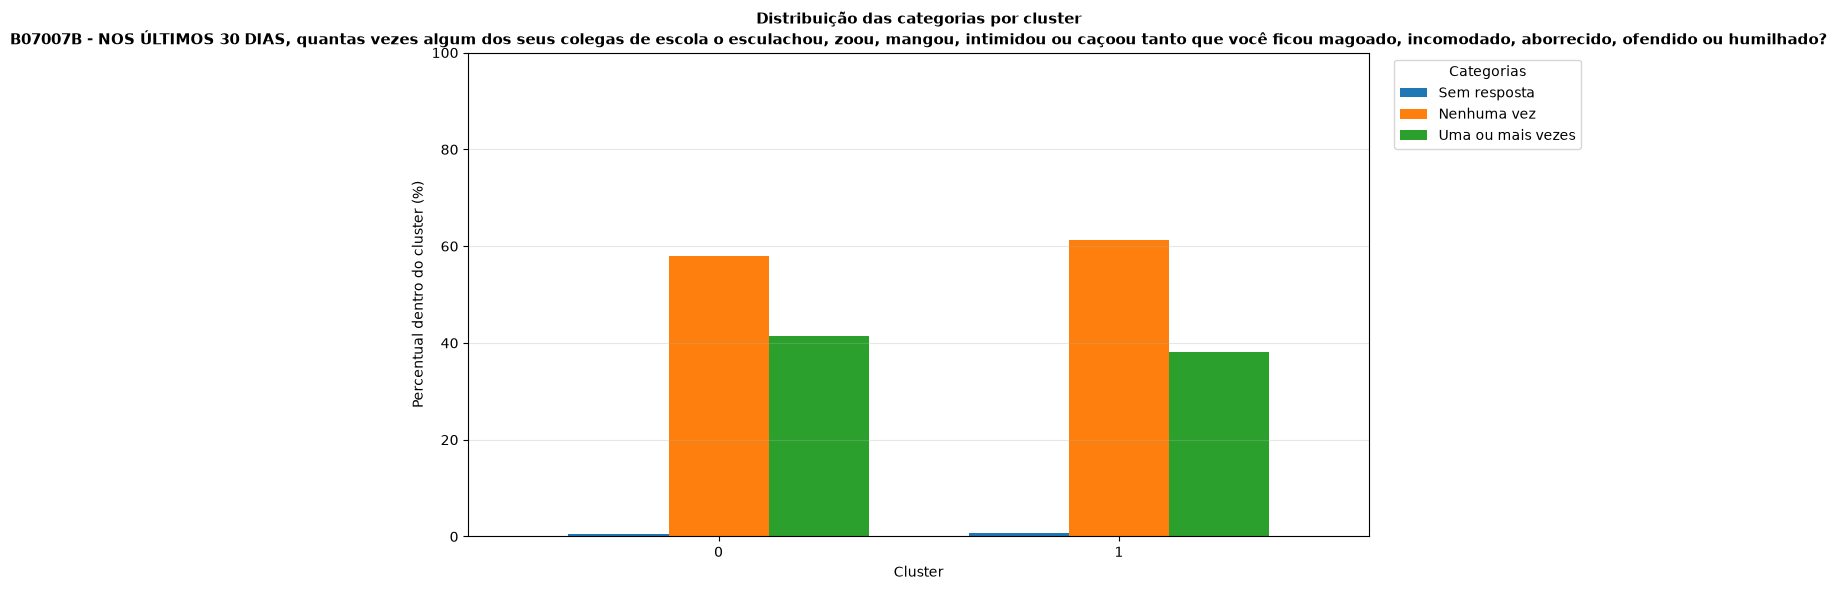


Analisando 17/39: B07011A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola se recusou a falar com você, deixou você de lado sem razão ou fez com que outros colegas deixassem de falar com você?


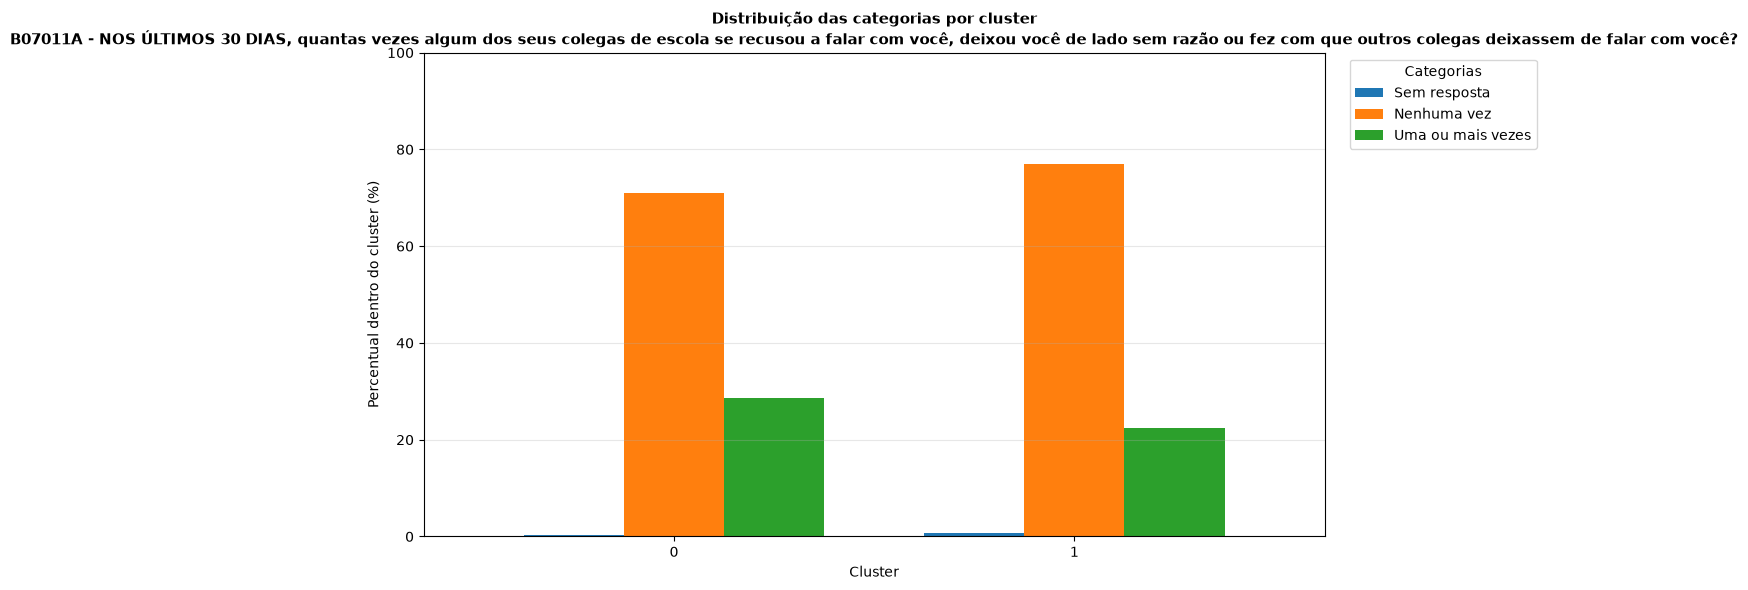


Analisando 18/39: B07012A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola bateu (deu socos, tapas, chutes, pontapés) em você ou o machucou fisicamente de outra forma?


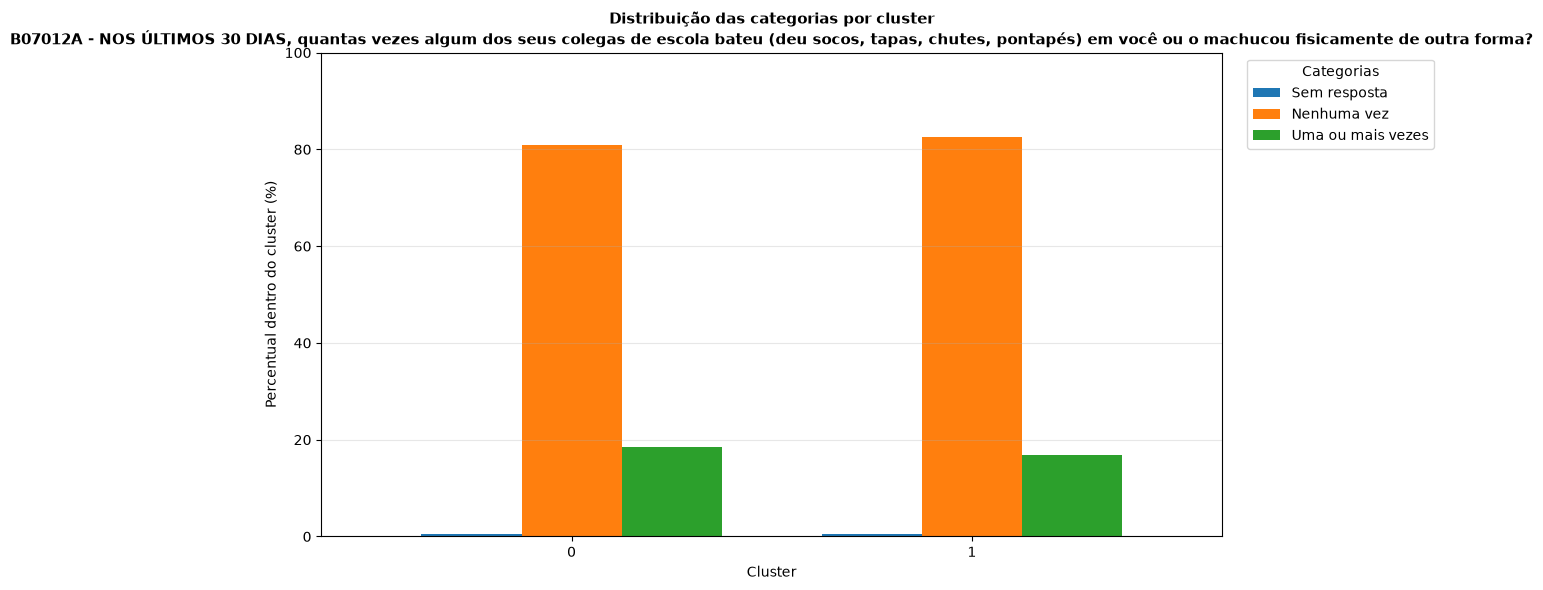


Analisando 19/39: B07013 - NOS ÚLTIMOS 30 DIAS, você se sentiu ameaçado(a), ofendido(a) ou humilhado(a) nas redes sociais ou aplicativos de celular?


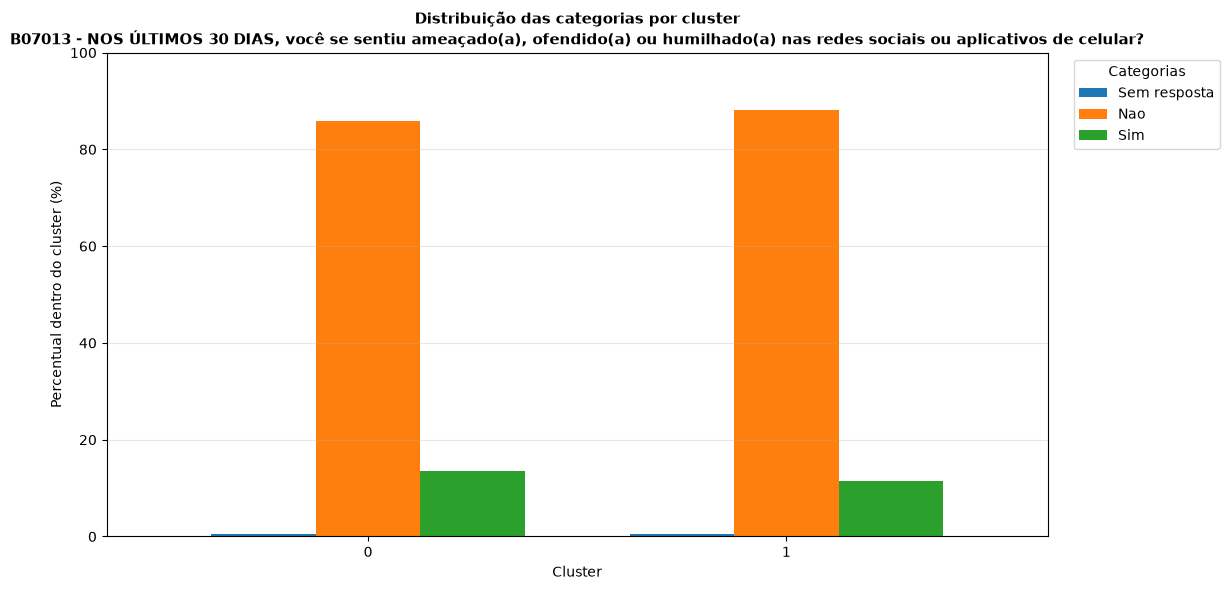


Analisando 20/39: B07009 - NOS ÚLTIMOS 30 DIAS, você esculachou, zombou, mangou, intimidou ou caçoou algum(a) de seus(suas) colegas da escola tanto que ele(ela) ficou magoado(a), aborrecido(a), ofendido(a) ou humilhado(a)?


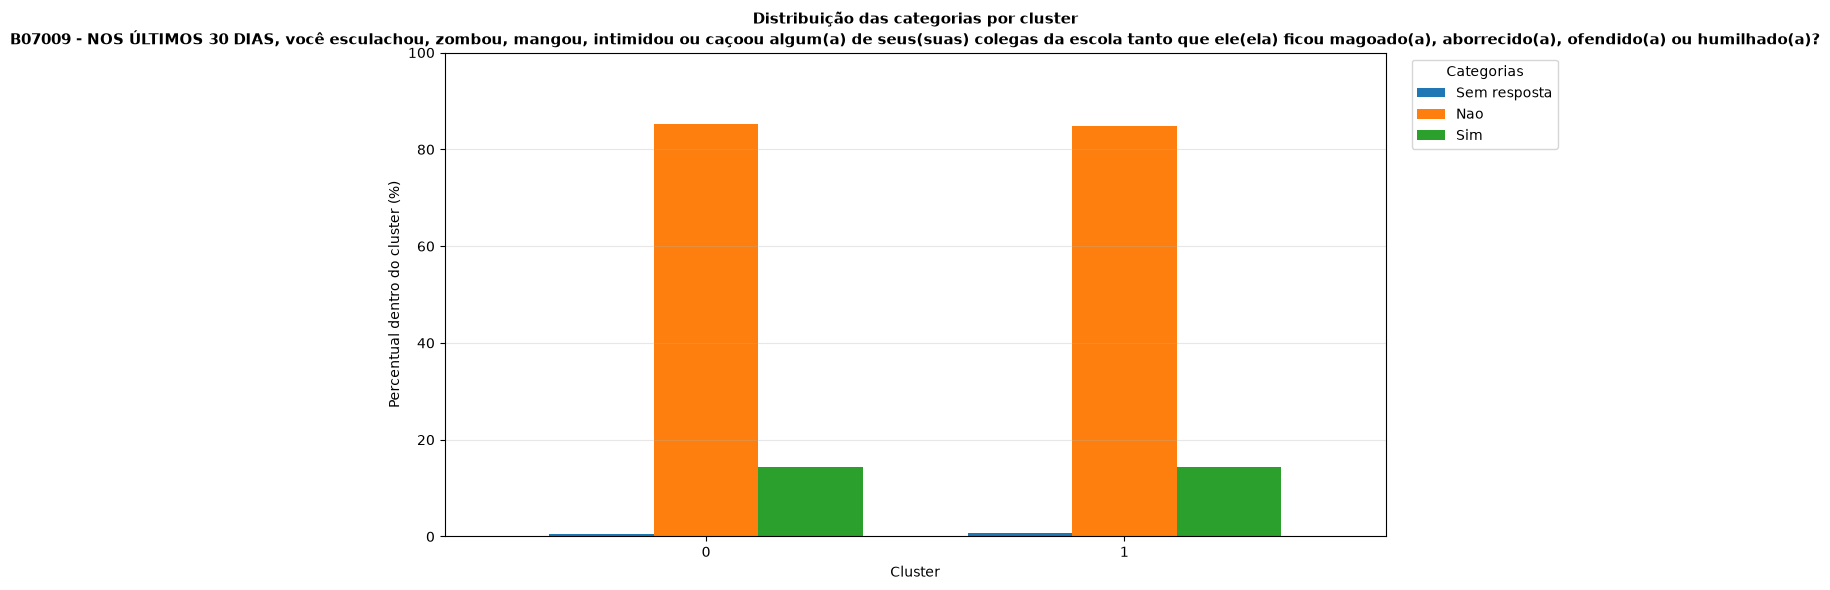


Analisando 21/39: B07016 - NOS ÚLTIMOS 30 DIAS, você ameaçou, ofendeu ou humilhou outras pessoas nas redes sociais ou aplicativos de celular?


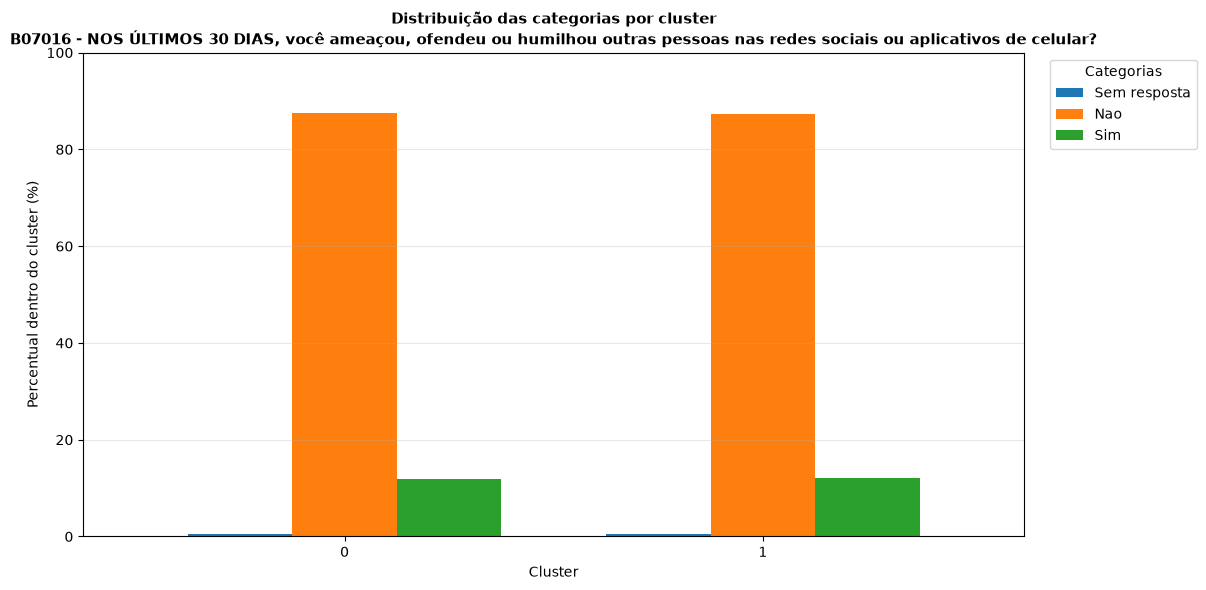


Analisando 22/39: B12003 - Quantos(as) amigos(as) próximos você tem?


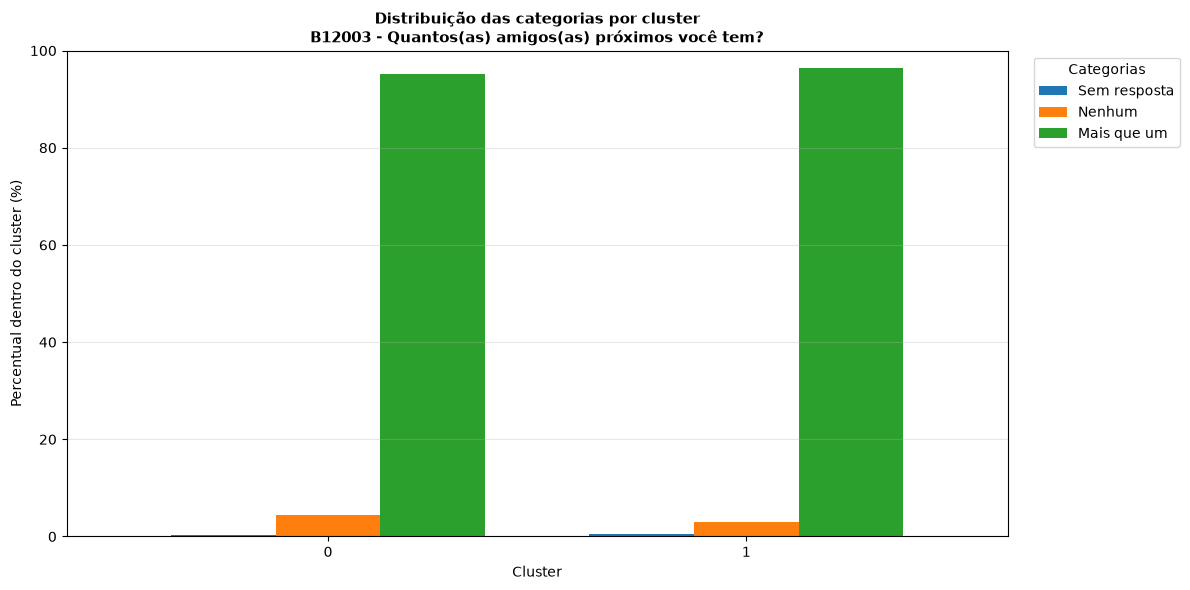


Analisando 23/39: B12004 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu muito preocupado com as coisas comuns do seu dia a dia como atividades da escola, competições esportivas, tarefas de casa, etc.?


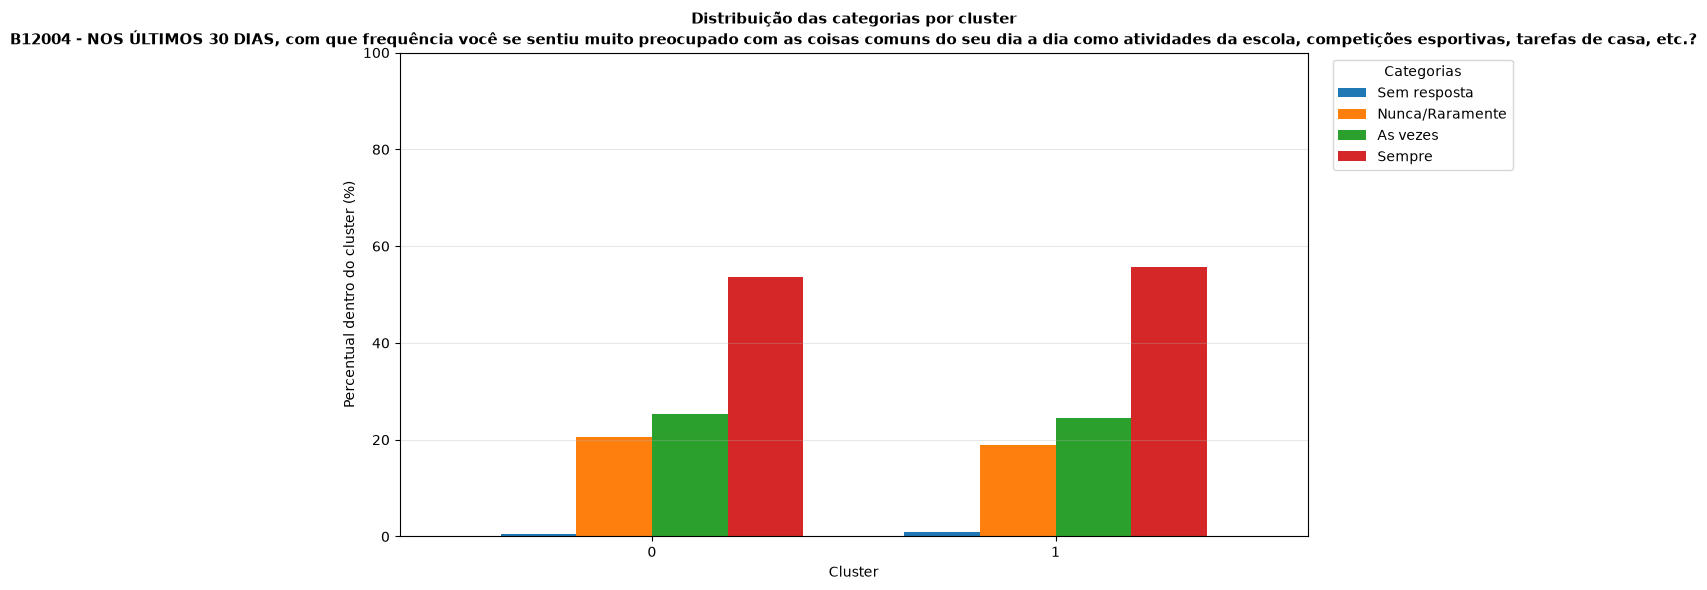


Analisando 24/39: B12005 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu triste?


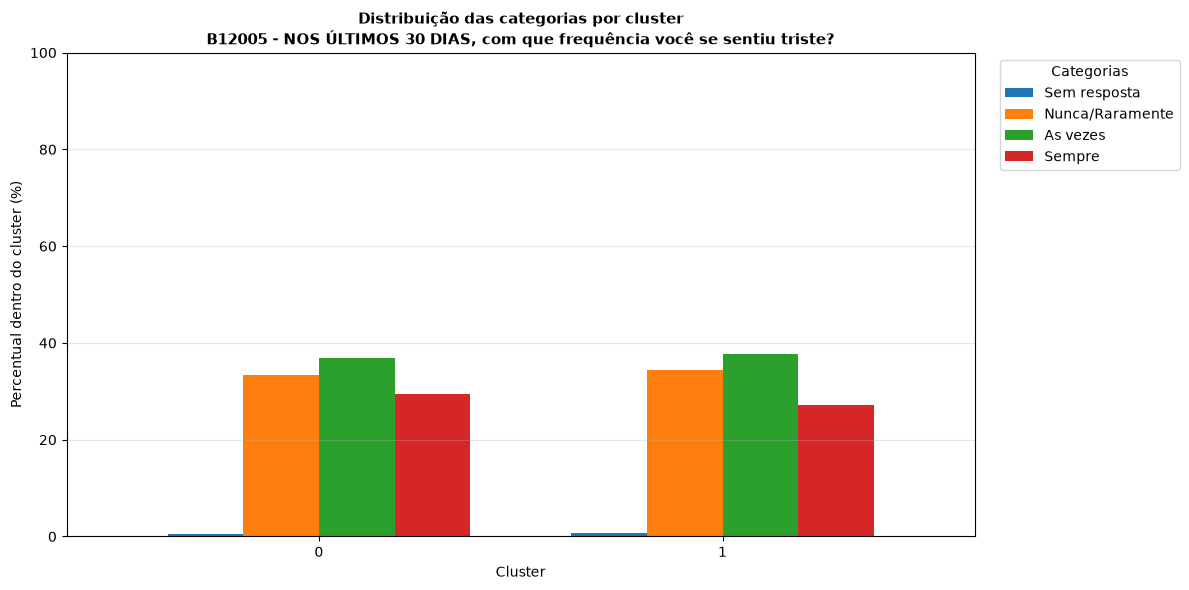


Analisando 25/39: B12006 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que ninguém se preocupa com você?


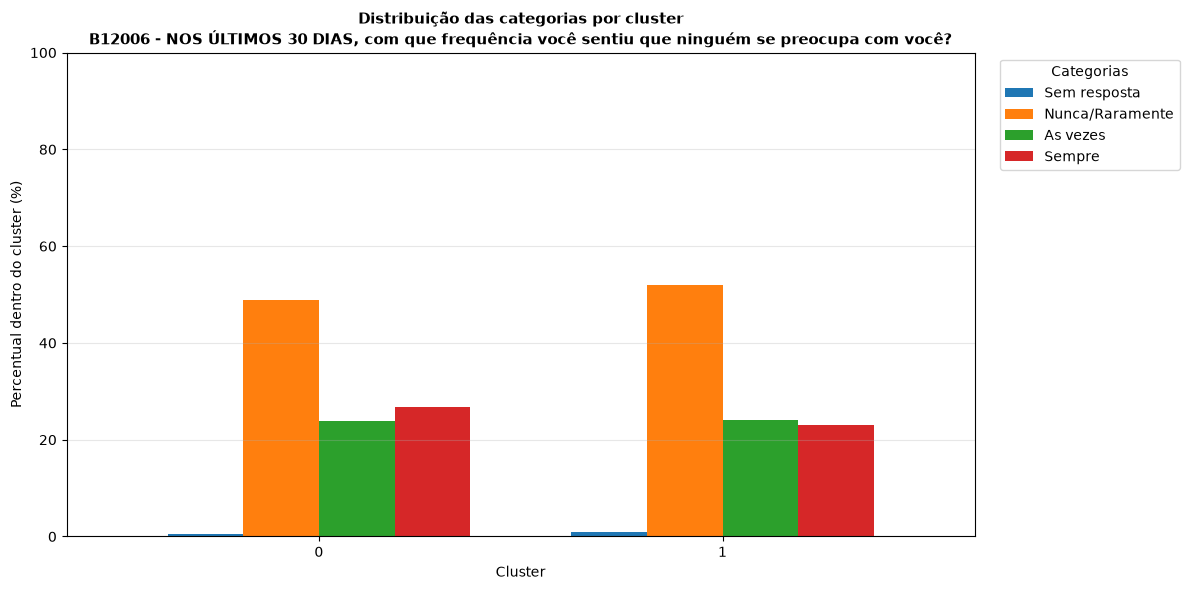


Analisando 26/39: B12007 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu irritado(a), nervoso(a) ou mal-humorado(a) por qualquer coisa?


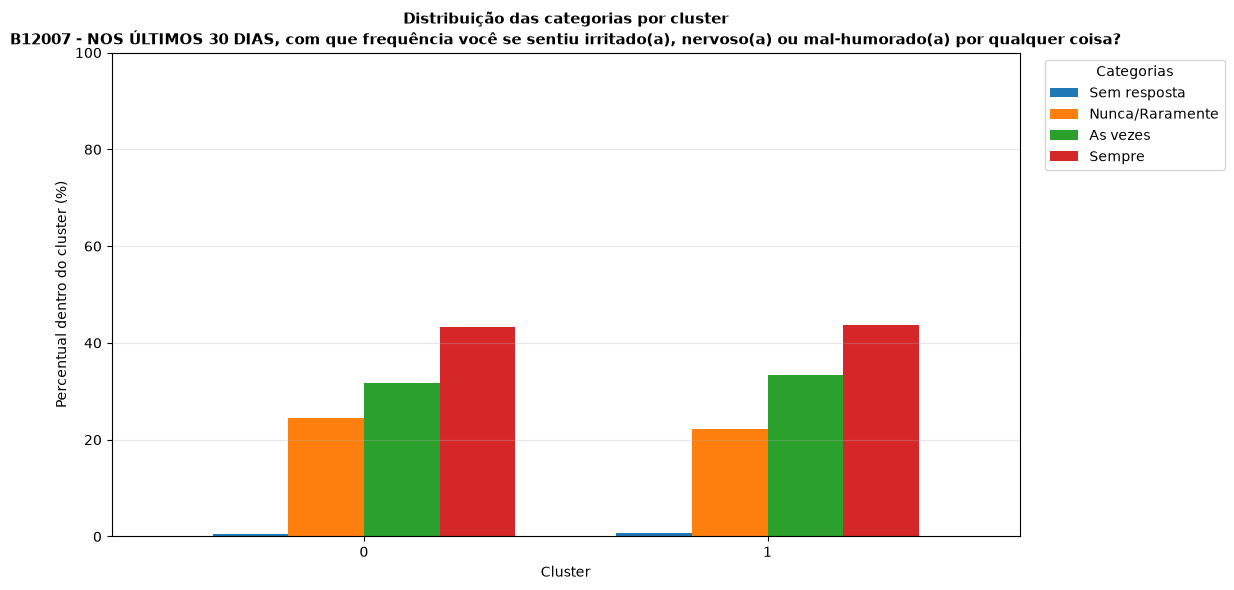


Analisando 27/39: B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?


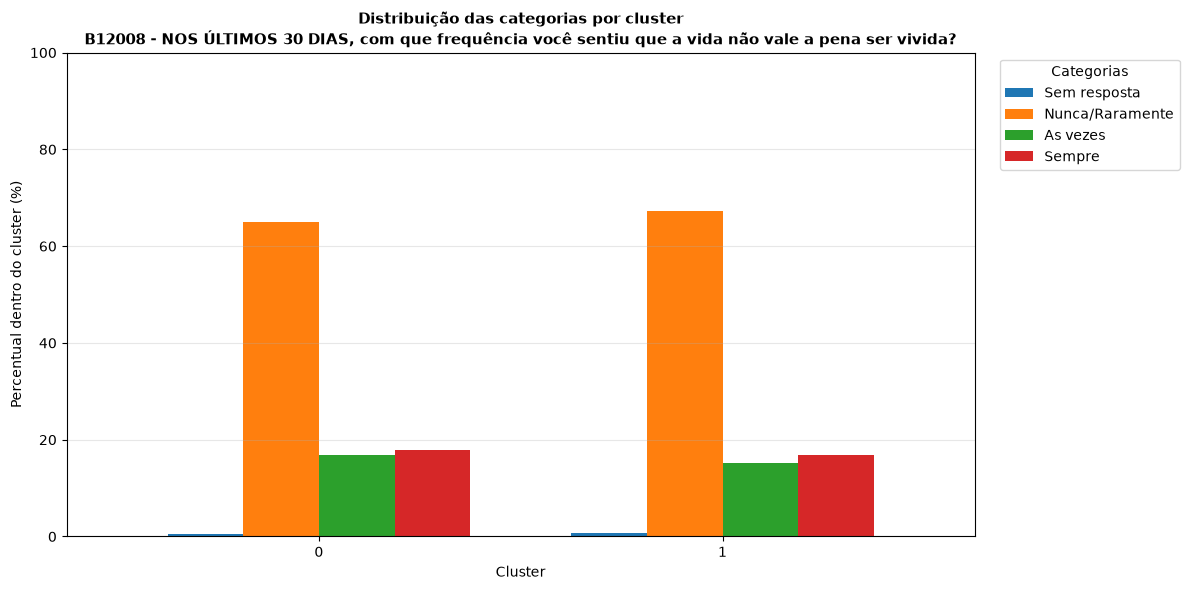


Analisando 28/39: B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?


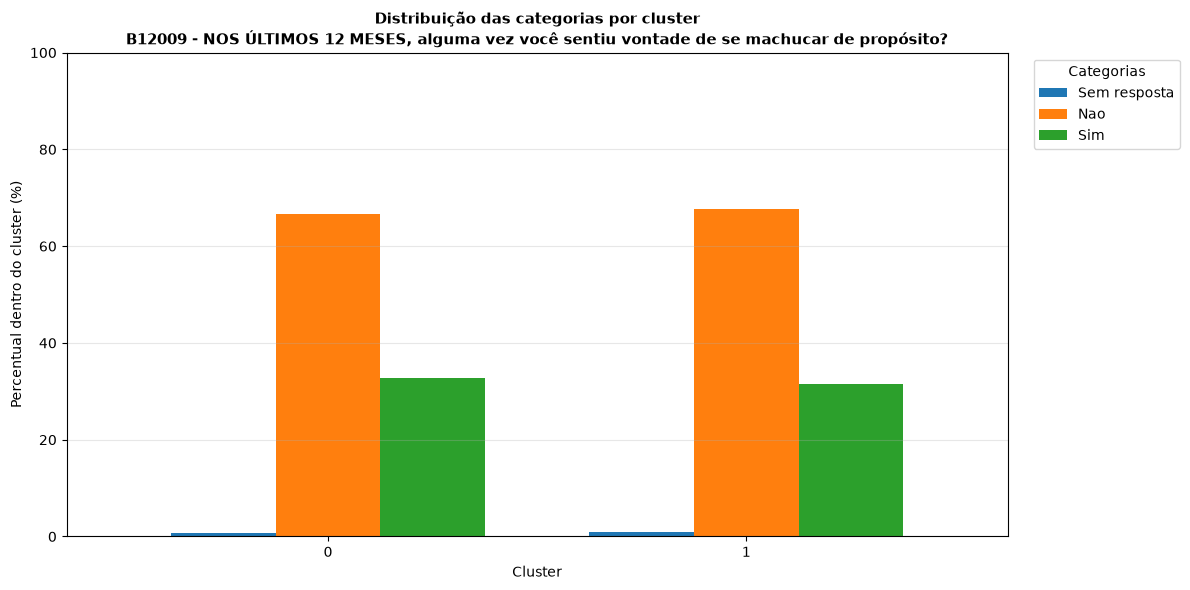


Analisando 29/39: B09001 - NOS ÚLTIMOS 30 DIAS, em quantos dias você deixou de ir à escola porque não se sentia seguro NO CAMINHO de casa para a escola ou da escola para casa?


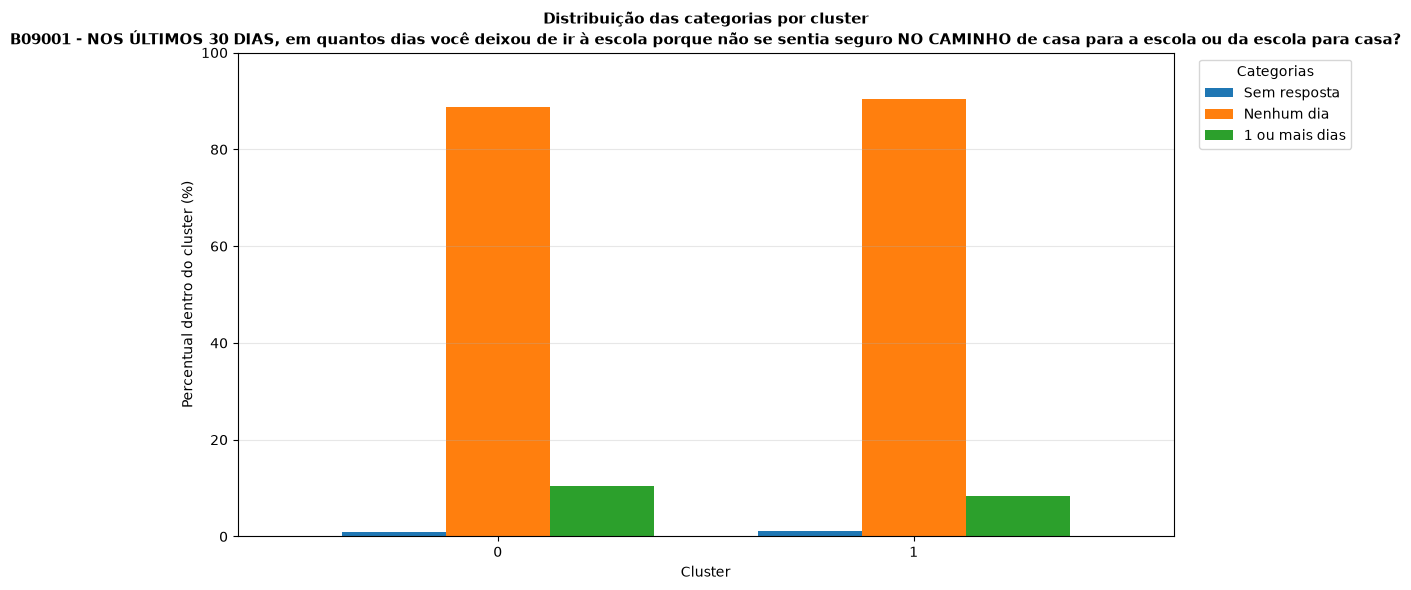


Analisando 30/39: B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?


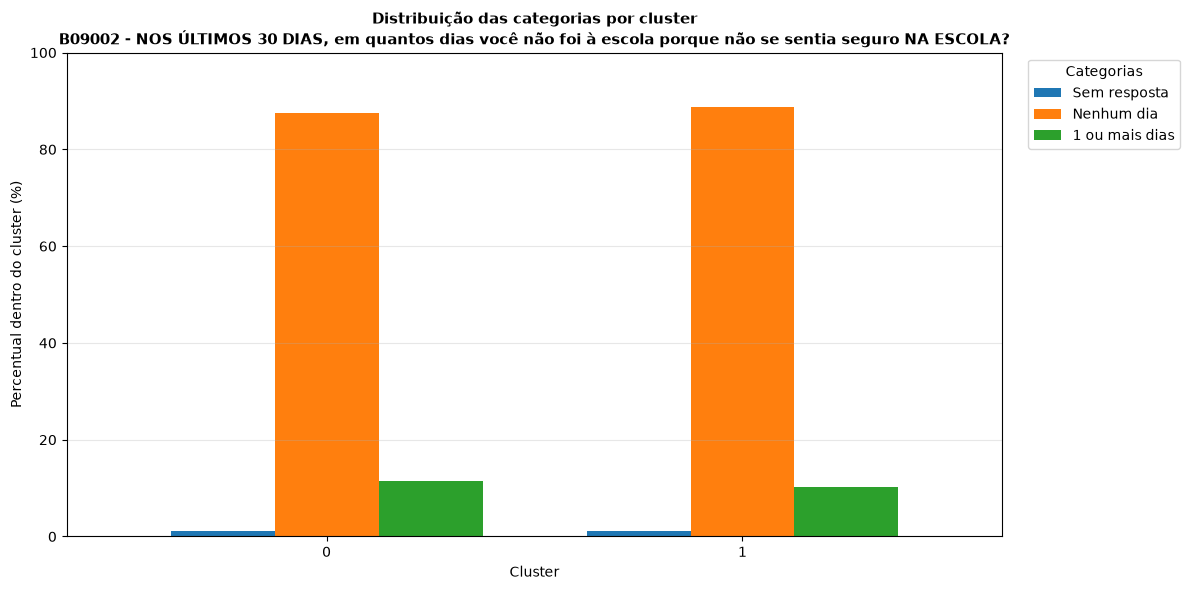


Analisando 31/39: B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?


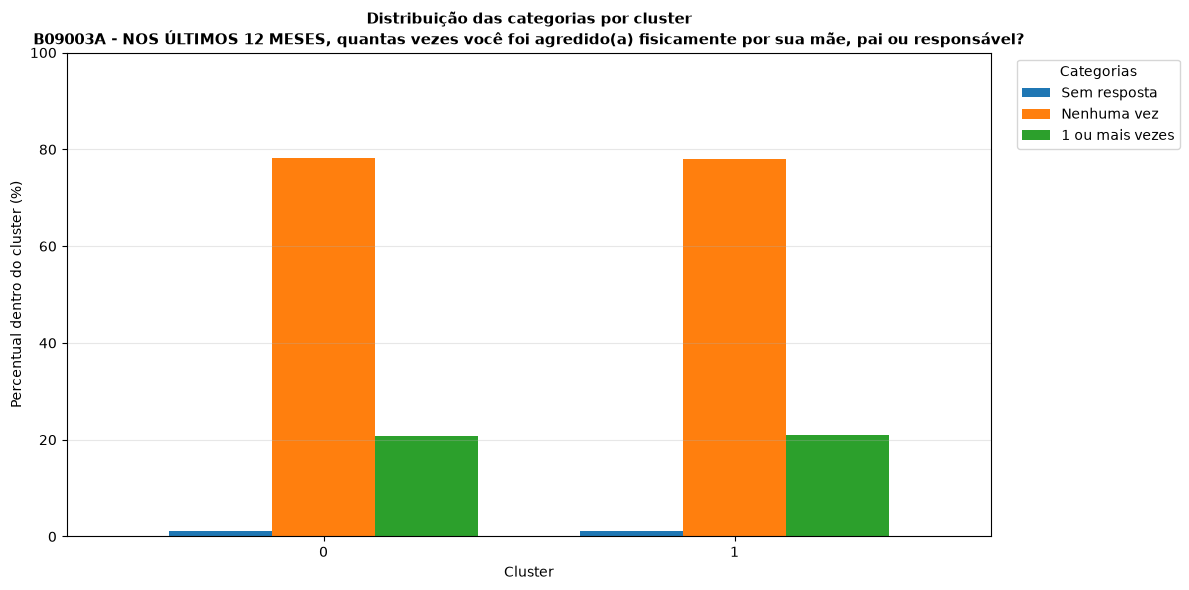


Analisando 32/39: B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?


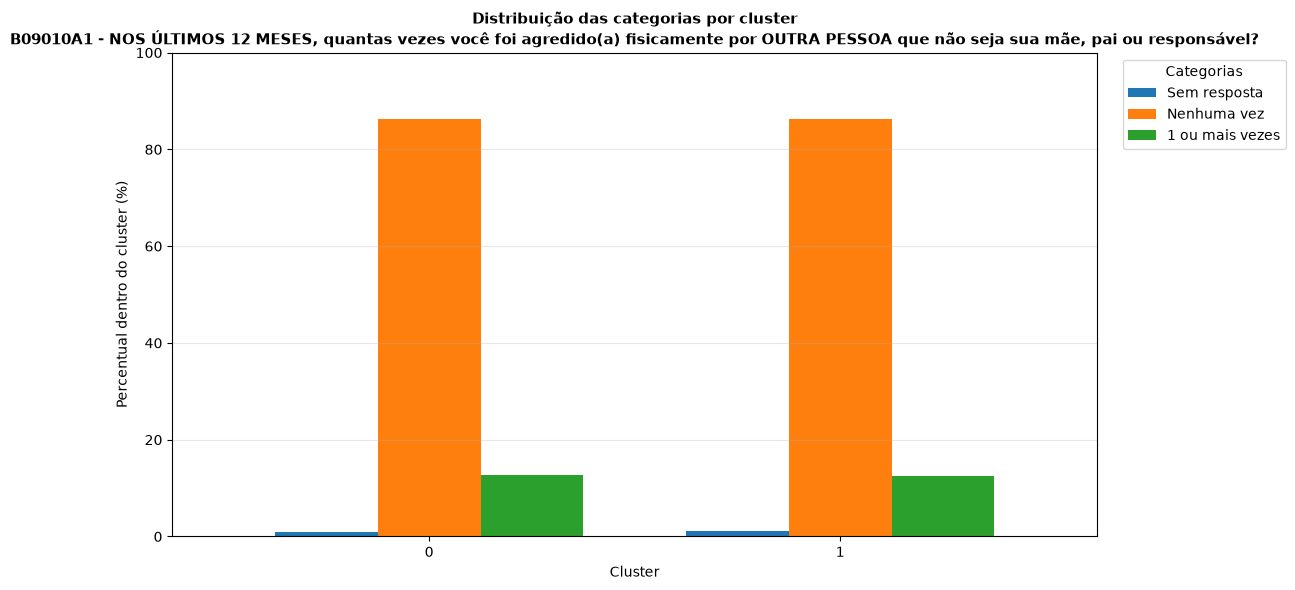


Analisando 33/39: B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?


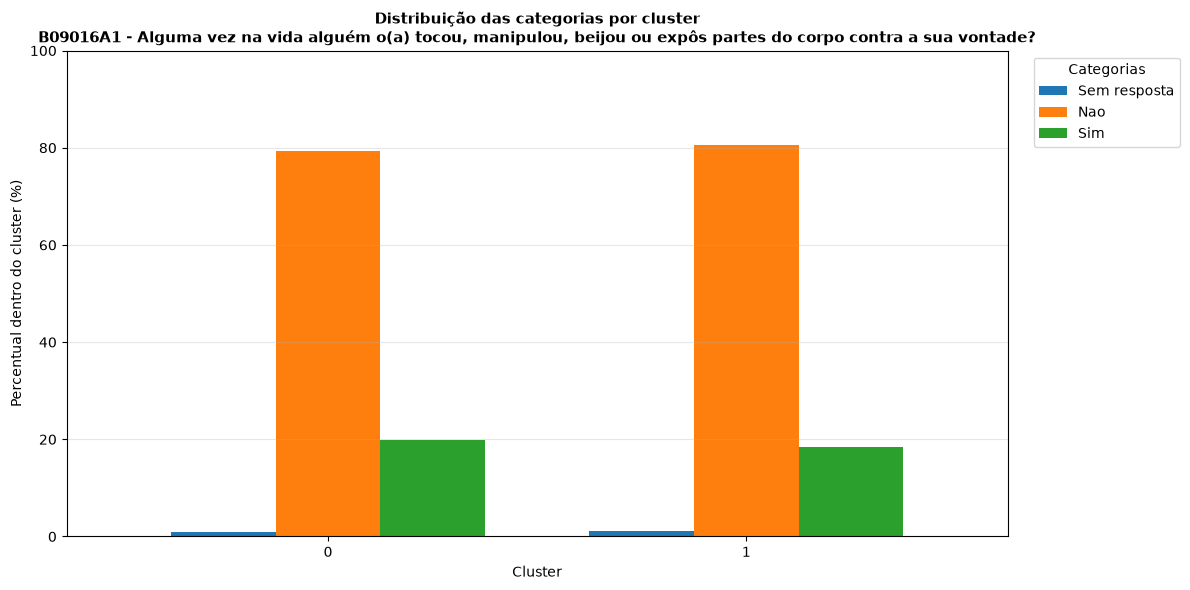


Analisando 34/39: B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?


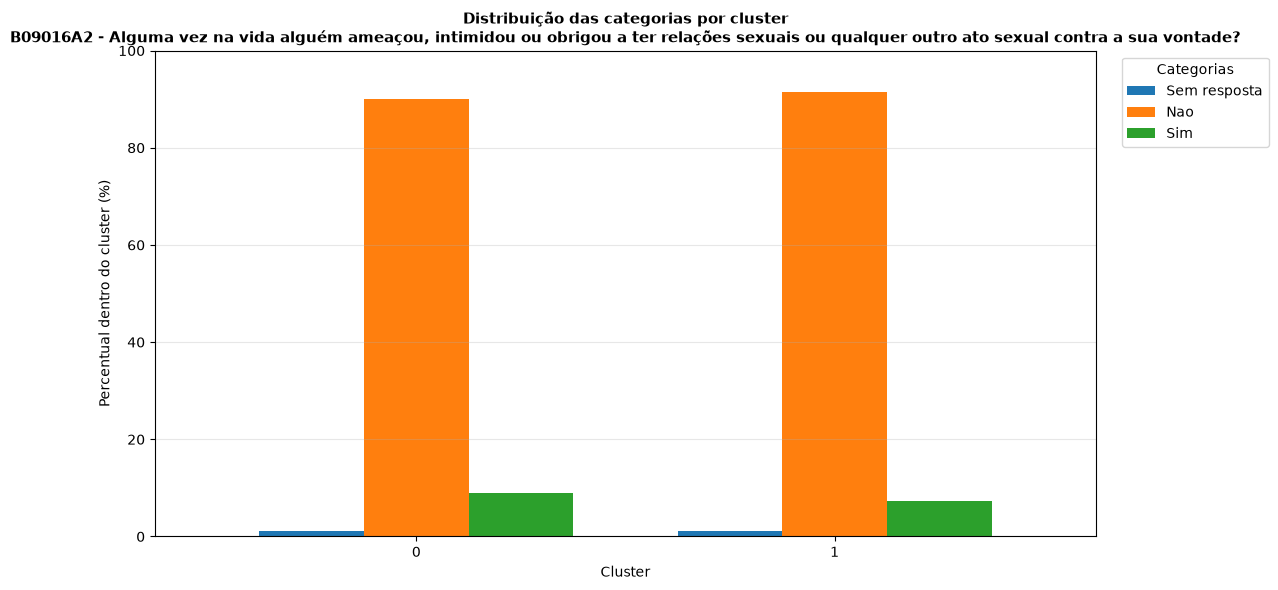


Analisando 35/39: E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes


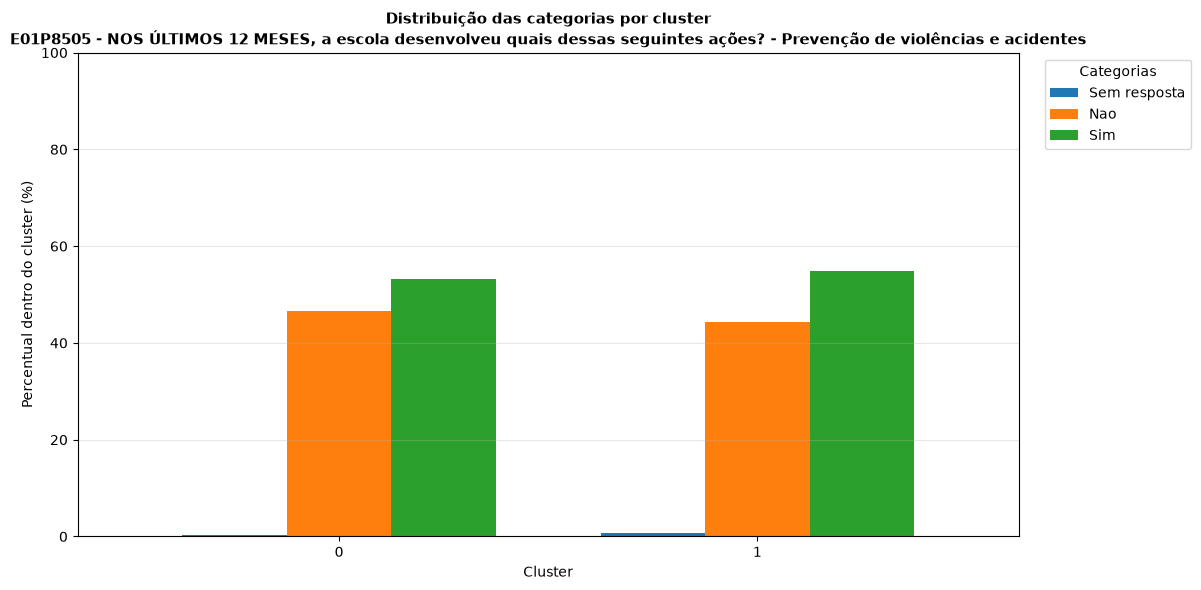


Analisando 36/39: E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola


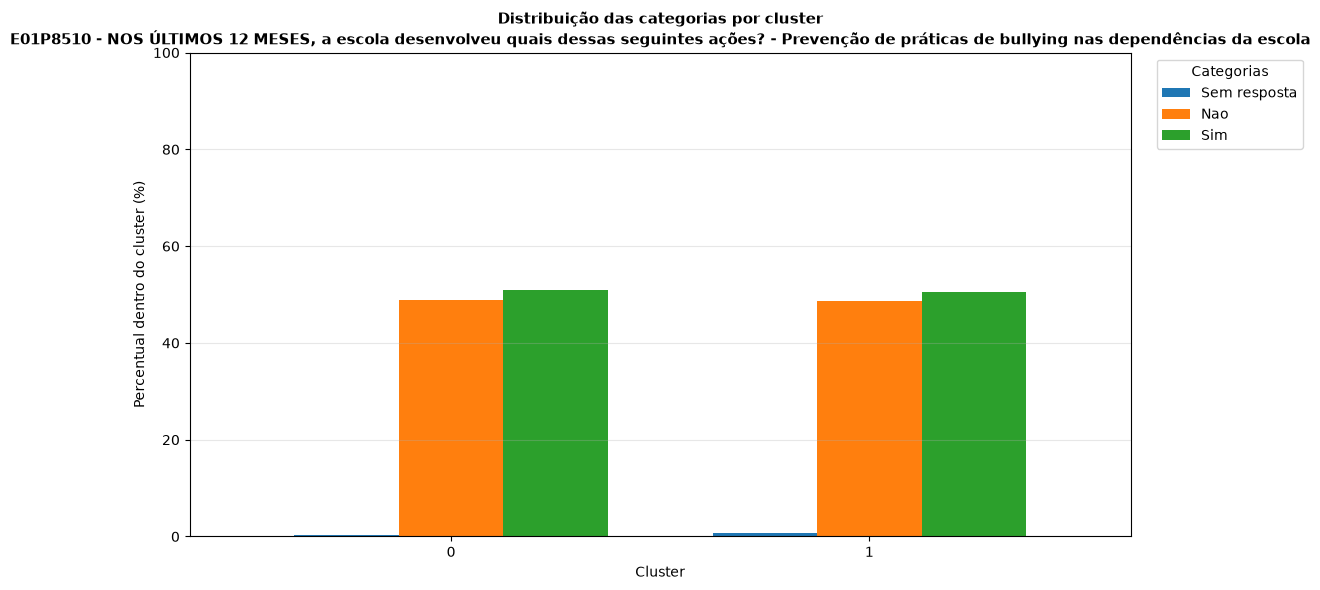


Analisando 37/39: E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?


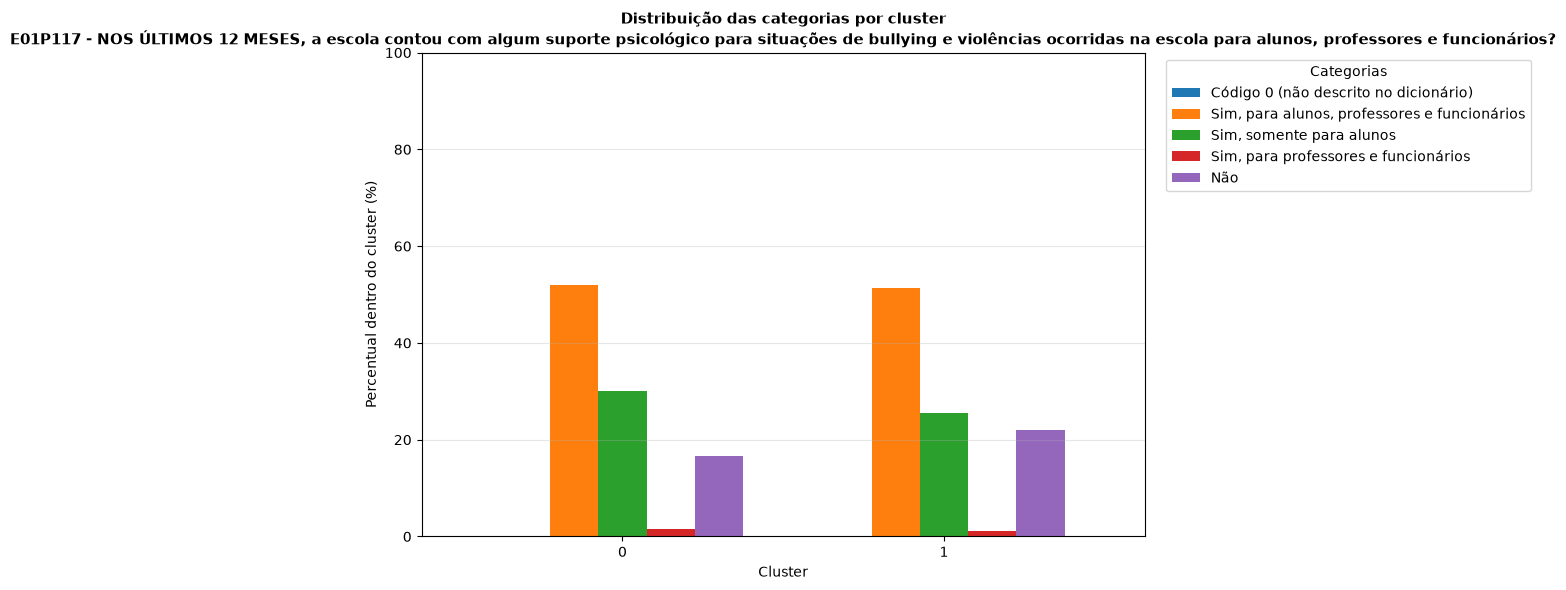


Analisando 38/39: E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental


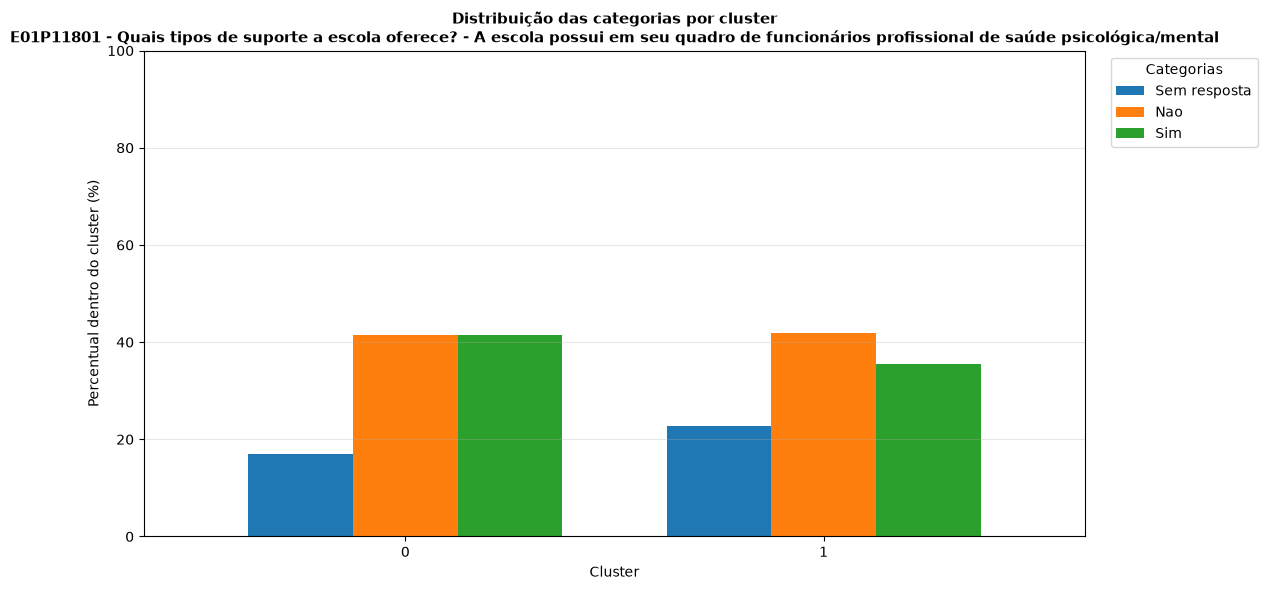


Analisando 39/39: E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental


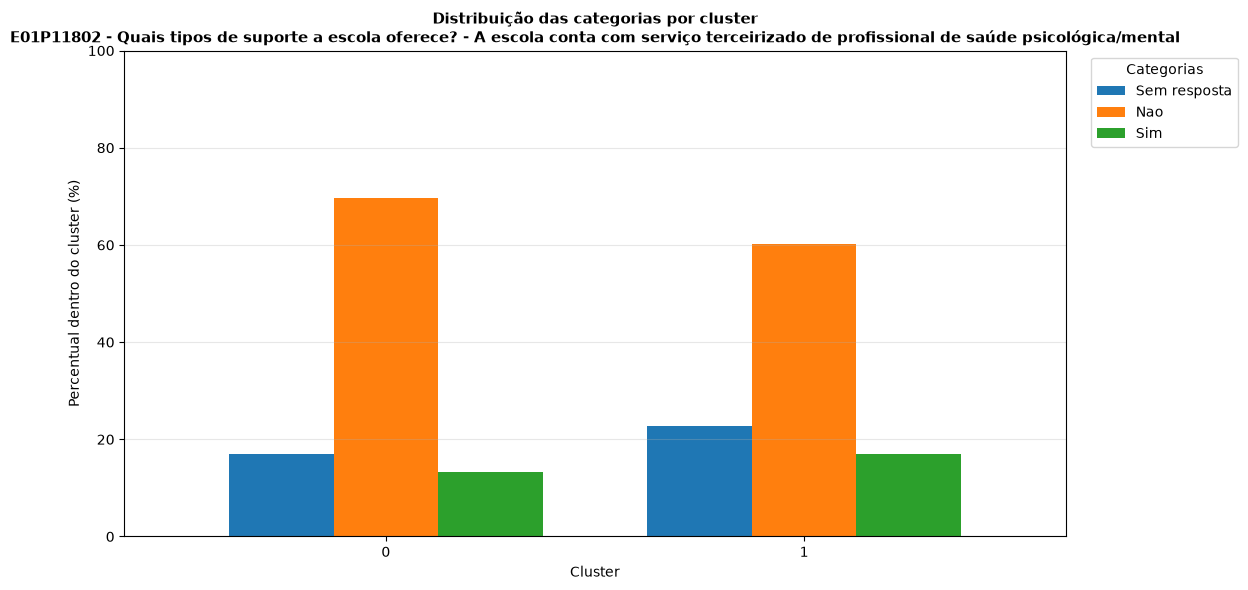



RANKING DAS VARIÁVEIS - V DE CRAMÉR


,Variavel,V_Cramer,P_valor
0,B01015B - Na sua casa tem computador ou notebook?,0.210272,9.882178e-49
1,B01002 - Qual é a sua cor ou raça?,0.200118,2.529242e-41
2,E01P11802 - Quais tipos de suporte a escola of...,0.099468,1.810621e-11
3,B01016 - Você tem acesso à internet em sua casa?,0.086272,8.299737e-09
4,E01P11801 - Quais tipos de suporte a escola of...,0.081356,6.511502e-08
5,B05002A - Alguma vez na vida você tomou um cop...,0.079610,1.315039e-07
6,"E01P117 - NOS ÚLTIMOS 12 MESES, a escola conto...",0.077578,4.688583e-06
7,"B07002 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.076227,2.183338e-06
8,B03010C - Quantas horas por dia você costuma f...,0.073214,1.514078e-06
9,"B07011A - NOS ÚLTIMOS 30 DIAS, quantas vezes a...",0.071994,2.357451e-06




DISTRIBUIÇÃO DAS CATEGORIAS POR CLUSTER


,Variavel,Categoria,Cluster,Frequencia,Percentual
0,CAPITAL - indica se é município da capital,Código 0 (não descrito no dicionário),0,1470,51.166029
1,CAPITAL - indica se é município da capital,Código 0 (não descrito no dicionário),1,937,44.052656
2,CAPITAL - indica se é município da capital,Capital,0,1403,48.833971
3,CAPITAL - indica se é município da capital,Capital,1,1190,55.947344
4,B01001A - Qual é o seu sexo?,Homem,0,1427,49.669335
...,...,...,...,...,...
251,E01P11802 - Quais tipos de suporte a escola of...,Sem resposta,1,483,22.708039
252,E01P11802 - Quais tipos de suporte a escola of...,Nao,0,2004,69.752872
253,E01P11802 - Quais tipos de suporte a escola of...,Nao,1,1281,60.225670
254,E01P11802 - Quais tipos de suporte a escola of...,Sim,0,383,13.331013



Análise concluída!
Nenhum arquivo externo foi gravado.
Os resultados permanecem disponíveis na memória:
- df_cramer
- df_distribuicao


In [24]:

# ============================================================
# CARACTERIZAÇÃO DOS CLUSTERS HAC - PENSE 2024
# Base original categórica + rótulos do dicionário
# SEM GRAVAÇÃO DE ARQUIVOS EXTERNOS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
from IPython.display import display

# ------------------------------------------------------------
# 1. FUNÇÕES AUXILIARES
# ------------------------------------------------------------

def normalizar_codigo(valor):

    if pd.isna(valor):
        return None

    valor = str(valor).strip()

    try:
        numero = float(valor)
        if numero.is_integer():
            return str(int(numero))
    except:
        pass

    return valor


def obter_rotulo(variavel, valor):

    if pd.isna(valor):
        return "Valor ausente (NaN)"

    codigo = normalizar_codigo(valor)

    rotulos = mapeamento_variaveis.get(variavel, {})

    return rotulos.get(
        codigo,
        f"Código {codigo} (não descrito no dicionário)"
    )


def calcular_cramer_v(tabela):

    # Remover linhas e colunas completamente vazias
    tabela = tabela.loc[
        tabela.sum(axis=1) > 0,
        tabela.sum(axis=0) > 0
    ]

    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        return np.nan, np.nan

    chi2, p_valor, _, _ = chi2_contingency(tabela)

    n = tabela.to_numpy().sum()

    if n == 0:
        return np.nan, np.nan

    menor_dimensao = min(
        tabela.shape[0] - 1,
        tabela.shape[1] - 1
    )

    v = np.sqrt(chi2 / (n * menor_dimensao))

    return v, p_valor


# ------------------------------------------------------------
# 2. PREPARAR RESULTADOS
# ------------------------------------------------------------

resultados_cramer = []
resultados_distribuicao = []

clusters = sorted(
    df_clusters["Cluster"].dropna().unique()
)

print("Clusters identificados:", clusters)
print("Total de indivíduos:", len(df_clusters))


# ------------------------------------------------------------
# 3. ANALISAR CADA UMA DAS 39 VARIÁVEIS
# ------------------------------------------------------------

for numero, variavel in enumerate(
    [c for c in df_clusters.columns if c != "Cluster"],
    start=1
):

    print(f"\nAnalisando {numero}/39: {variavel}")

    # --------------------------------------------------------
    # Criar cópia com categorias identificadas por rótulos
    # --------------------------------------------------------

    dados = pd.DataFrame({
        "Cluster": df_clusters["Cluster"],
        "Categoria": df_clusters[variavel].apply(
            lambda x: obter_rotulo(variavel, x)
        )
    })

    # --------------------------------------------------------
    # Frequências absolutas
    # --------------------------------------------------------

    frequencias = pd.crosstab(
        dados["Categoria"],
        dados["Cluster"],
        dropna=False
    )

    frequencias = frequencias.reindex(
        columns=clusters,
        fill_value=0
    )

    # --------------------------------------------------------
    # Percentuais dentro de cada cluster
    # --------------------------------------------------------

    percentuais = frequencias.div(
        frequencias.sum(axis=0).replace(0, np.nan),
        axis=1
    ) * 100

    # --------------------------------------------------------
    # Guardar distribuição em formato longo
    # --------------------------------------------------------

    for categoria in frequencias.index:

        for cluster in clusters:

            resultados_distribuicao.append({

                "Variavel": variavel,
                "Categoria": categoria,
                "Cluster": cluster,
                "Frequencia": frequencias.loc[
                    categoria, cluster
                ],
                "Percentual": percentuais.loc[
                    categoria, cluster
                ]

            })

    # --------------------------------------------------------
    # Qui-quadrado e V de Cramér
    # --------------------------------------------------------

    v_cramer, p_valor = calcular_cramer_v(
        frequencias
    )

    resultados_cramer.append({

        "Variavel": variavel,
        "V_Cramer": v_cramer,
        "P_valor": p_valor

    })

    # --------------------------------------------------------
    # GRÁFICO COMPARATIVO
    # --------------------------------------------------------

    grafico = percentuais.T

    fig, ax = plt.subplots(figsize=(12, 6))

    grafico.plot(
        kind="bar",
        ax=ax,
        width=0.75
    )

    ax.set_title(
        f"Distribuição das categorias por cluster\n{variavel}",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlabel("Cluster")
    ax.set_ylabel("Percentual dentro do cluster (%)")

    ax.set_ylim(0, 100)

    ax.legend(
        title="Categorias",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

    plt.xticks(rotation=0)
    plt.tight_layout()

    # Apresentar diretamente no Jupyter Notebook
    plt.show()
    plt.close()


# ------------------------------------------------------------
# 4. CONSOLIDAR RESULTADOS
# ------------------------------------------------------------

df_cramer = pd.DataFrame(resultados_cramer)

df_distribuicao = pd.DataFrame(
    resultados_distribuicao
)

df_cramer = df_cramer.sort_values(
    "V_Cramer",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 5. APRESENTAR RANKING DO V DE CRAMÉR
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("RANKING DAS VARIÁVEIS - V DE CRAMÉR")
print("=" * 70)

display(df_cramer)


# ------------------------------------------------------------
# 6. APRESENTAR DISTRIBUIÇÃO DAS CATEGORIAS
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("DISTRIBUIÇÃO DAS CATEGORIAS POR CLUSTER")
print("=" * 70)

display(df_distribuicao)


# ------------------------------------------------------------
# 7. FINALIZAÇÃO
# ------------------------------------------------------------

print("\nAnálise concluída!")
print("Nenhum arquivo externo foi gravado.")
print("Os resultados permanecem disponíveis na memória:")
print("- df_cramer")
print("- df_distribuicao")


In [4]:
# ============================================================
# 11. RECUPERAÇÃO DAS VARIÁVEIS ORIGINAIS
# HAC - PENSE 2024
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 11.1. CARREGAR BASE ORIGINAL
# ------------------------------------------------------------

arquivo_original = (
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"
)

df_original = pd.read_feather(arquivo_original)

print("BASE ORIGINAL")
print("Dimensões:", df_original.shape)

# ------------------------------------------------------------
# 11.2. VALIDAR CORRESPONDÊNCIA COM A BASE MCA
# ------------------------------------------------------------

if len(df_original) != len(df_mca):
    raise ValueError(
        "As bases original e MCA possuem quantidades diferentes "
        "de registros. Não é seguro associar as linhas por posição. "
        "Será necessário utilizar um identificador comum."
    )

# Recuperar posições dos indivíduos que entraram no HAC
posicoes_validas = df_mca.index.get_indexer(indices_validos)

if np.any(posicoes_validas < 0):
    raise ValueError("Não foi possível recuperar os índices originais.")

posicoes_originais = posicoes_validas[indices_hac]

# Recuperar respostas categóricas dos mesmos indivíduos
df_clusters = df_original.iloc[posicoes_originais].copy()

# Associar os clusters encontrados pelo HAC
df_clusters["Cluster"] = clusters_hac

print("\nBASE FINAL PARA INTERPRETAÇÃO")

print("Quantidade de indivíduos:", len(df_clusters))
print("Quantidade de variáveis:", len(df_clusters.columns) - 1)

print("\nDistribuição dos clusters:")

display(
    df_clusters["Cluster"]
    .value_counts()
    .sort_index()
)

print("\nPercentual de cada cluster:")

display(
    (
        df_clusters["Cluster"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

BASE ORIGINAL
Dimensões: (118036, 39)

BASE FINAL PARA INTERPRETAÇÃO
Quantidade de indivíduos: 5000
Quantidade de variáveis: 39

Distribuição dos clusters:


Cluster
0    2873
1    2127
Name: count, dtype: int64


Percentual de cada cluster:


Cluster
0    57.46
1    42.54
Name: proportion, dtype: float64

PERFIL DE RESPOSTAS POR CLUSTER


,Variavel,Categoria,Cluster,Percentual
0,CAPITAL - indica se é município da capital,0,0,51.17
1,CAPITAL - indica se é município da capital,0,1,44.05
2,CAPITAL - indica se é município da capital,1,0,48.83
3,CAPITAL - indica se é município da capital,1,1,55.95
4,B01001A - Qual é o seu sexo?,1,0,49.67
...,...,...,...,...
251,E01P11802 - Quais tipos de suporte a escola of...,0,1,22.71
252,E01P11802 - Quais tipos de suporte a escola of...,1,0,69.75
253,E01P11802 - Quais tipos de suporte a escola of...,1,1,60.23
254,E01P11802 - Quais tipos de suporte a escola of...,3,0,13.33


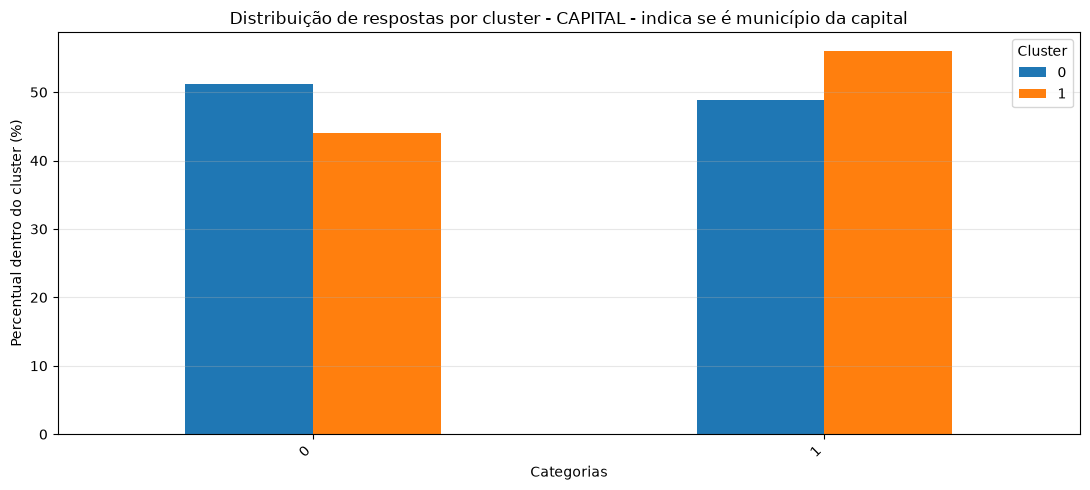

In [5]:
# ============================================================
# 12. PERFIL DESCRITIVO DOS CLUSTERS
# ============================================================

variaveis = [
    c for c in df_clusters.columns
    if c != "Cluster"
    and not c.lower().startswith(("id_", "codigo", "cod_"))
]

# Converter respostas para formato categórico de análise
df_analise = df_clusters[variaveis].copy()

for col in variaveis:
    df_analise[col] = (
        df_analise[col]
        .astype("object")
        .fillna("Não informado")
        .astype(str)
    )

df_analise["Cluster"] = df_clusters["Cluster"].values

# ------------------------------------------------------------
# FUNÇÃO PARA CALCULAR DISTRIBUIÇÃO
# ------------------------------------------------------------

perfis = []

for variavel in variaveis:

    tabela = pd.crosstab(
        df_analise[variavel],
        df_analise["Cluster"],
        normalize="columns"
    ) * 100

    for categoria in tabela.index:

        for cluster in tabela.columns:

            perfis.append({
                "Variavel": variavel,
                "Categoria": categoria,
                "Cluster": cluster,
                "Percentual": tabela.loc[categoria, cluster]
            })

df_perfis = pd.DataFrame(perfis)

print("PERFIL DE RESPOSTAS POR CLUSTER")

display(df_perfis.round(2))

# ------------------------------------------------------------
# EXEMPLO DE VISUALIZAÇÃO DE UMA VARIÁVEL
# ------------------------------------------------------------

variavel_exemplo = variaveis[0]

tabela_exemplo = pd.crosstab(
    df_analise[variavel_exemplo],
    df_analise["Cluster"],
    normalize="columns"
) * 100

tabela_exemplo.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title(
    f"Distribuição de respostas por cluster - {variavel_exemplo}"
)

plt.xlabel("Categorias")
plt.ylabel("Percentual dentro do cluster (%)")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Cluster")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

ASSOCIAÇÃO ENTRE VARIÁVEIS E CLUSTERS


,Variavel,Qui_Quadrado,Graus_Liberdade,P_Valor,V_Cramer,Categorias,P_Valor_Ajustado
6,B01015B - Na sua casa tem computador ou notebook?,221.07187,2,0.00000,0.21027,3,0.00000
3,B01002 - Qual é a sua cor ou raça?,200.23571,5,0.00000,0.20012,6,0.00000
38,E01P11802 - Quais tipos de suporte a escola of...,49.46953,2,0.00000,0.09947,3,0.00000
7,B01016 - Você tem acesso à internet em sua casa?,37.21408,2,0.00000,0.08627,3,0.00000
37,E01P11801 - Quais tipos de suporte a escola of...,33.09422,2,0.00000,0.08136,3,0.00000
10,B05002A - Alguma vez na vida você tomou um cop...,31.68846,2,0.00000,0.07961,3,0.00000
36,"E01P117 - NOS ÚLTIMOS 12 MESES, a escola conto...",30.09166,4,0.00000,0.07758,5,0.00002
11,"B07002 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",29.05242,3,0.00000,0.07623,4,0.00001
9,B03010C - Quantas horas por dia você costuma f...,26.80141,2,0.00000,0.07321,3,0.00001
16,"B07011A - NOS ÚLTIMOS 30 DIAS, quantas vezes a...",25.91586,2,0.00000,0.07199,3,0.00001


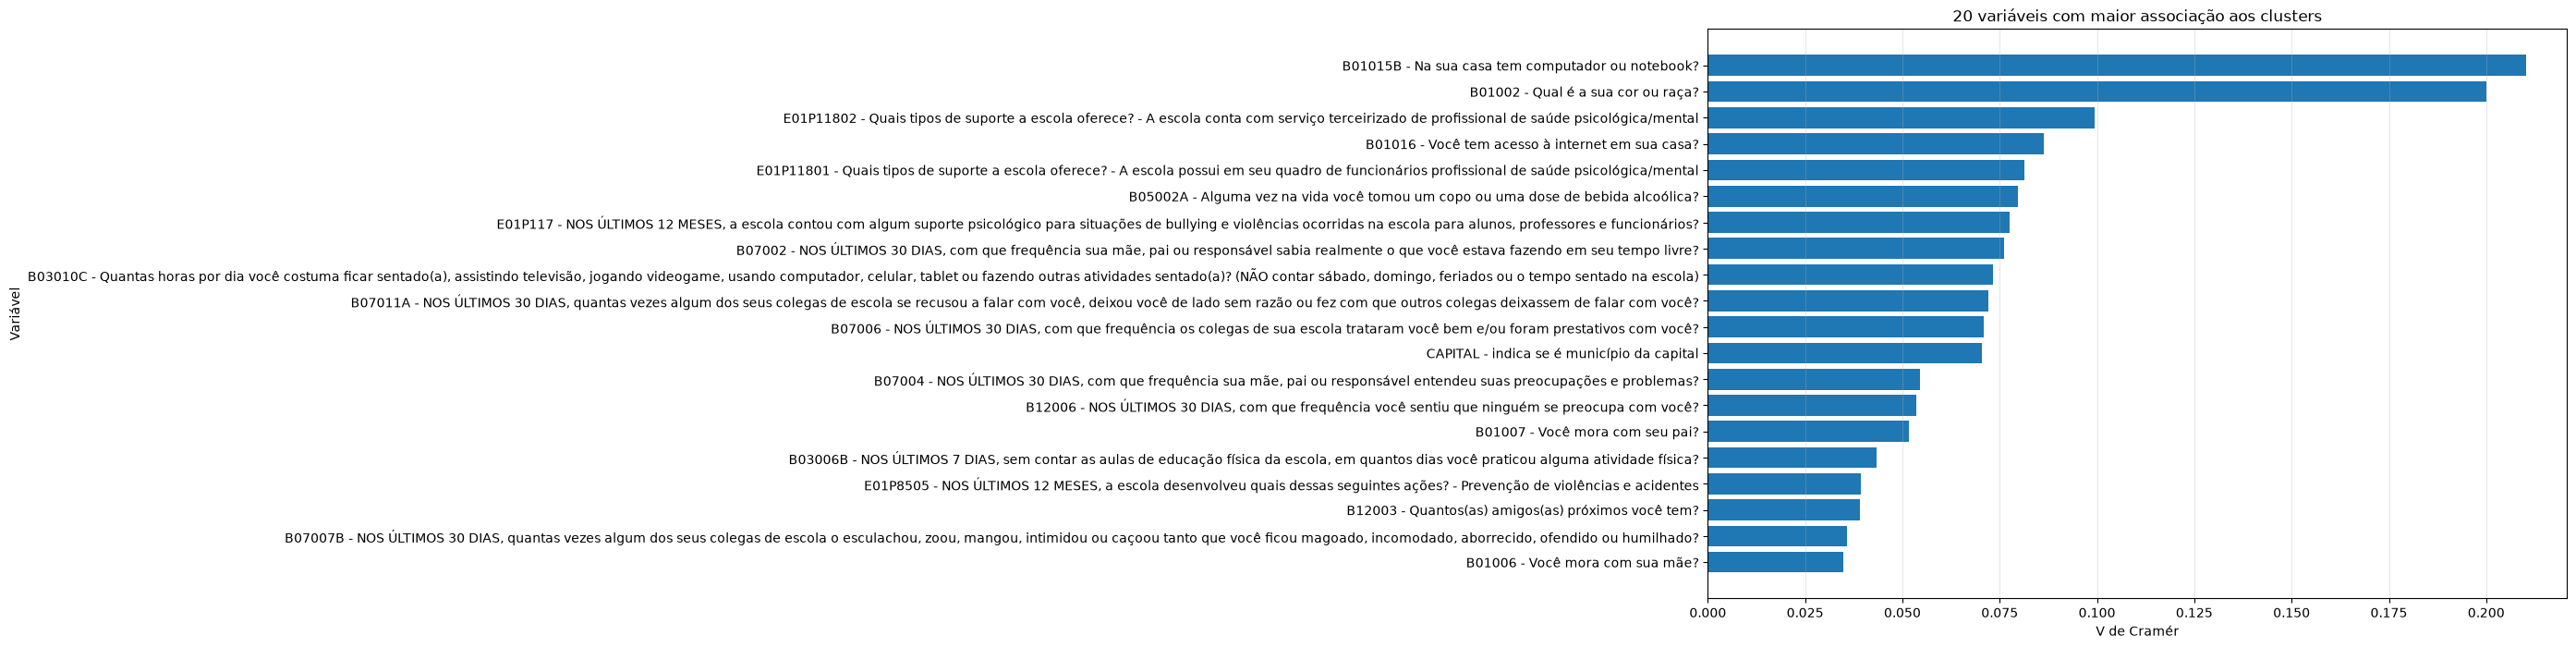

In [6]:
# ============================================================
# 13. ASSOCIAÇÃO ENTRE VARIÁVEIS E CLUSTERS
# QUI-QUADRADO + V DE CRAMÉR
# ============================================================

resultados = []

for variavel in variaveis:

    tabela = pd.crosstab(
        df_analise[variavel],
        df_analise["Cluster"]
    )

    # Eliminar categorias sem observações
    tabela = tabela.loc[
        tabela.sum(axis=1) > 0,
        tabela.sum(axis=0) > 0
    ]

    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        continue

    qui2, p_valor, gl, esperado = chi2_contingency(
        tabela,
        correction=False
    )

    n = tabela.to_numpy().sum()

    menor_dimensao = min(
        tabela.shape[0] - 1,
        tabela.shape[1] - 1
    )

    if menor_dimensao <= 0:
        continue

    v_cramer = np.sqrt(
        qui2 / (n * menor_dimensao)
    )

    resultados.append({
        "Variavel": variavel,
        "Qui_Quadrado": qui2,
        "Graus_Liberdade": gl,
        "P_Valor": p_valor,
        "V_Cramer": v_cramer,
        "Categorias": tabela.shape[0]
    })

df_associacao = pd.DataFrame(resultados)

# ------------------------------------------------------------
# CORREÇÃO DE MÚLTIPLOS TESTES
# BENJAMINI-HOCHBERG
# ------------------------------------------------------------

if len(df_associacao) > 0:

    df_associacao["P_Valor_Ajustado"] = multipletests(
        df_associacao["P_Valor"],
        method="fdr_bh"
    )[1]

    df_associacao = df_associacao.sort_values(
        "V_Cramer",
        ascending=False
    )

print("ASSOCIAÇÃO ENTRE VARIÁVEIS E CLUSTERS")

display(df_associacao.round(5))

# ------------------------------------------------------------
# GRÁFICO - VARIÁVEIS MAIS ASSOCIADAS
# ------------------------------------------------------------

top_variaveis = df_associacao.head(20).sort_values(
    "V_Cramer"
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_variaveis["Variavel"],
    top_variaveis["V_Cramer"]
)

plt.title("20 variáveis com maior associação aos clusters")
plt.xlabel("V de Cramér")
plt.ylabel("Variável")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# 14. RESÍDUOS PADRONIZADOS AJUSTADOS
# CATEGORIAS MAIS CARACTERÍSTICAS DOS CLUSTERS
# ============================================================

from scipy.stats import norm

resultados_residuos = []

for variavel in variaveis:

    tabela = pd.crosstab(
        df_analise[variavel],
        df_analise["Cluster"]
    )

    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        continue

    qui2, p, gl, esperado = chi2_contingency(
        tabela,
        correction=False
    )

    observado = tabela.to_numpy()

    total = observado.sum()

    proporcao_linha = observado.sum(axis=1) / total
    proporcao_coluna = observado.sum(axis=0) / total

    denominador = np.sqrt(
        esperado *
        (1 - proporcao_linha[:, None]) *
        (1 - proporcao_coluna[None, :])
    )

    residuos = np.divide(
        observado - esperado,
        denominador,
        out=np.zeros_like(esperado, dtype=float),
        where=denominador > 0
    )

    for i, categoria in enumerate(tabela.index):

        for j, cluster in enumerate(tabela.columns):

            z = residuos[i, j]

            p_residuo = 2 * norm.sf(abs(z))

            resultados_residuos.append({
                "Variavel": variavel,
                "Categoria": categoria,
                "Cluster": cluster,
                "Frequencia": observado[i, j],
                "Percentual": (
                    observado[i, j] /
                    observado[:, j].sum() * 100
                ),
                "Residuo_Ajustado": z,
                "P_Valor": p_residuo
            })

df_residuos = pd.DataFrame(resultados_residuos)

# Correção de múltiplos testes para os resíduos
df_residuos["P_Valor_Ajustado"] = multipletests(
    df_residuos["P_Valor"],
    method="fdr_bh"
)[1]

# Categorias mais características
df_residuos["Magnitude"] = (
    df_residuos["Residuo_Ajustado"].abs()
)

df_residuos = df_residuos.sort_values(
    "Magnitude",
    ascending=False
)

print("CATEGORIAS MAIS ASSOCIADAS AOS CLUSTERS")

display(
    df_residuos[
        [
            "Variavel",
            "Categoria",
            "Cluster",
            "Frequencia",
            "Percentual",
            "Residuo_Ajustado",
            "P_Valor_Ajustado"
        ]
    ].head(50).round(4)
)

CATEGORIAS MAIS ASSOCIADAS AOS CLUSTERS


,Variavel,Categoria,Cluster,Frequencia,Percentual,Residuo_Ajustado,P_Valor_Ajustado
40,B01015B - Na sua casa tem computador ou notebook?,3,0,1547,53.8462,-14.8677,0.0000
41,B01015B - Na sua casa tem computador ou notebook?,3,1,1583,74.4241,14.8677,0.0000
39,B01015B - Na sua casa tem computador ou notebook?,1,1,543,25.5289,-14.8562,0.0000
38,B01015B - Na sua casa tem computador ou notebook?,1,0,1324,46.0842,14.8562,0.0000
14,B01002 - Qual é a sua cor ou raça?,1,0,942,32.7880,-13.2676,0.0000
15,B01002 - Qual é a sua cor ou raça?,1,1,1094,51.4339,13.2676,0.0000
21,B01002 - Qual é a sua cor ou raça?,4,1,706,33.1923,-11.8619,0.0000
20,B01002 - Qual é a sua cor ou raça?,4,0,1436,49.9826,11.8619,0.0000
252,E01P11802 - Quais tipos de suporte a escola of...,1,0,2004,69.7529,7.0162,0.0000
253,E01P11802 - Quais tipos de suporte a escola of...,1,1,1281,60.2257,-7.0162,0.0000


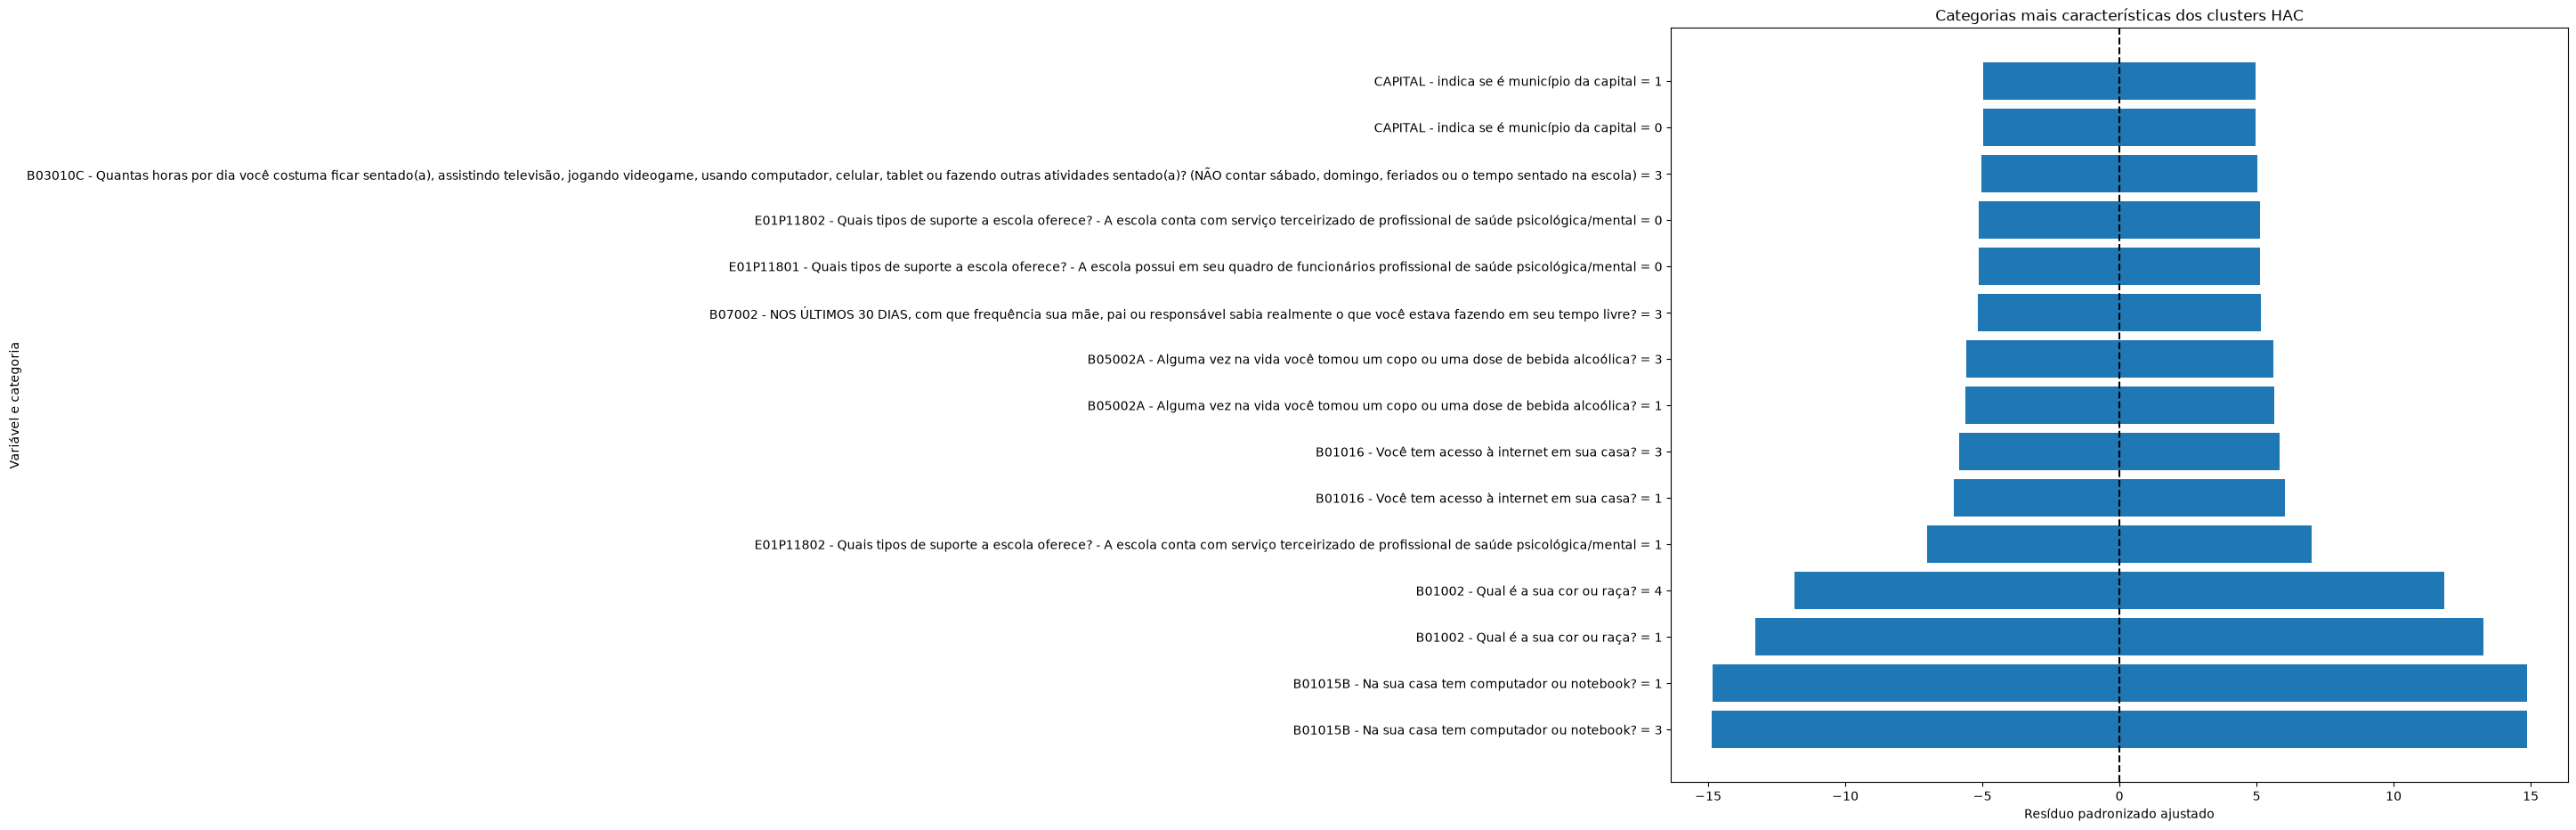

In [8]:
# ============================================================
# 15. GRÁFICO DAS CATEGORIAS MAIS CARACTERÍSTICAS
# ============================================================

top_residuos = df_residuos[
    df_residuos["P_Valor_Ajustado"] < 0.05
].copy()

top_residuos = top_residuos.head(30)

top_residuos["Descricao"] = (
    top_residuos["Variavel"].astype(str)
    + " = "
    + top_residuos["Categoria"].astype(str)
)

top_residuos = top_residuos.sort_values(
    "Residuo_Ajustado"
)

plt.figure(figsize=(13, 11))

plt.barh(
    top_residuos["Descricao"],
    top_residuos["Residuo_Ajustado"]
)

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.title(
    "Categorias mais características dos clusters HAC"
)

plt.xlabel("Resíduo padronizado ajustado")
plt.ylabel("Variável e categoria")

plt.tight_layout()
plt.show()